# Lab 8 — Edge Deployment
### MobileNetV2 → full-integer (INT8) TensorFlow Lite on a simulated 256 MB / single-core device

**Submitted by:** Anson Dias &nbsp;·&nbsp; **Date:** 15 October 2026

**Pipeline.** A pre-trained MobileNetV2 image classifier is converted to TensorFlow Lite with **full-integer
quantisation** (a representative calibration dataset is used to calibrate the activation ranges). The resulting
**FlatBuffer** is parsed to find which operators were quantised and which needed a **float fallback**. The model is
then deployed on a **simulated edge device**: the kernel enforces a limit of **256 MB of RAM and one CPU core**.
**Inference latency** and **peak memory** are measured at **224×224, 160×160 and 96×96**, and the
**latency–accuracy–memory trade-off surface** is plotted. The written report (Section 12) explains **why not every
TFLite operator supports INT8** and what that means for real edge deployment.

| # | Section | # | Section |
|---|---|---|---|
| 0 | Summary of results | 7 | Simulated edge device (256 MB, 1 core) |
| 1 | Environment & configuration | 8 | Latency & peak-memory benchmark |
| 2 | Data: calibration & evaluation sets | 9 | Accuracy on the device |
| 3 | Pre-trained MobileNetV2 | 10 | Latency–accuracy–memory trade-off surface |
| 4 | TFLite conversion with full-integer quantisation | 11 | Case study: what a float fallback costs |
| 5 | FlatBuffer inspection: INT8 kernels vs float fallback | 12 | **Written report** |
| 6 | Per-layer quantisation error | 13 | References |

## 0. Summary of results

All measurements were taken on the simulated edge device: a kernel-enforced **256 MiB** memory limit, **one CPU
core**, and a single-threaded LiteRT interpreter. Accuracy is strict 1000-way ImageNet classification of all
3,925 Imagenette validation images, computed *on the device* by the same `.tflite` files that were timed.

| input | precision | file (MB) | GMACs | top-1 | top-5 | mean latency (ms) | p95 (ms) | peak RSS (MB) | model-attributable (MB) |
|---|---|---|---|---|---|---|---|---|---|
| 224×224 | FP32 | 14.01 | 0.301 | 80.25% | 97.38% | 6.39 | 8.88 | 72.5 | 38.6 |
| 224×224 | **INT8** | 4.04 | 0.301 | 79.54% | 96.94% | 4.67 | 5.82 | 48.7 | 14.8 |
| 160×160 | FP32 | 14.01 | 0.154 | 77.71% | 96.38% | 3.67 | 5.00 | 68.3 | 34.4 |
| 160×160 | **INT8** | 4.04 | 0.154 | 76.87% | 96.08% | 2.35 | 2.52 | 47.0 | 13.1 |
| 96×96 | FP32 | 14.01 | 0.056 | 67.39% | 89.91% | 1.62 | 2.27 | 65.5 | 31.6 |
| 96×96 | **INT8** | 4.04 | 0.056 | 61.22% | 86.17% | 0.99 | 1.11 | 45.9 | 12.0 |

**Key findings**

* **Full-integer quantisation covered every operator.** The deployed FlatBuffer has 69
  operators: 67 compute ops on INT8 kernels and 2 integer requantisations at the uint8
  I/O. **No float fallback** was needed. Weights are stored as int8 with per-channel scales, and the file shrinks
  from 14.0 MB to 4.04 MB (3.47×).
* **INT8 is 1.37–1.64× faster** than FP32 on one core and needs
  **2.6× less model memory**. The cost is
  **0.71 pp** top-1 at 224 px and 0.84 pp at 160 px, but **6.17 pp at 96 px**,
  where predictions are less confident and even confident ones flip more often.
* **Resolution is the bigger lever:** latency follows the MAC count (224 → 160 → 96 px =
  0.301 → 0.154 → 0.056 GMACs). Every configuration fits in 256 MB with at least
  72 % headroom; about 34 MB of each peak is the Python + LiteRT
  runtime itself.
* **Recommended deployment: INT8 at 160×160.** It reaches 76.9 % top-1 at
  2.35 ms and 47 MB. That is
  2.7× faster than FP32-224 for
  3.4 pp of accuracy. INT8-224 is the choice
  when accuracy matters most.
* **Float fallback is real and costly.** 10 of 23 probed ops (e.g. `square`, `pow`, `sin`,
  `elu`) have no INT8 kernel, and the converter inserted float islands **silently**, even in integer-only mode.
  One `POW` in the pre-processing of MobileNetV2 added **+2.27 ms (+48%)**
  per image. It also cut the share of MACs a single-partition integer accelerator could run from 100 % to 0 %. An
  INT8-friendly rewrite (exp/log) restored an all-integer graph.

## 1. Environment & configuration

The model is converted with full TensorFlow on the workstation. On the "device" only the stand-alone **LiteRT**
runtime (`ai_edge_litert`, the successor of `tflite_runtime`) is used: from TF 2.20 onwards `tf.lite.Interpreter`
is deprecated in favour of it, and it is the package that would be installed on a real board.

In [1]:
import os, io, re, sys, json, glob, time, shutil, tarfile, platform, contextlib, subprocess, urllib.request, warnings
import importlib.metadata as md
from concurrent.futures import ThreadPoolExecutor

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

@contextlib.contextmanager
def quiet():
    # Silence Python prints *and* the native C++ log lines TF / LiteRT write straight to fd 2.
    sys.stdout.flush(); sys.stderr.flush()
    saved = os.dup(2)
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(io.StringIO()):
        os.dup2(devnull.fileno(), 2)
        try:
            yield
        finally:
            os.dup2(saved, 2)
            os.close(saved)

with quiet():
    import tensorflow as tf
    from tensorflow.lite.python import schema_py_generated as tflschema   # FlatBuffer schema (Python)
    from ai_edge_litert.interpreter import Interpreter

tf.get_logger().setLevel("ERROR")
SEED = 8
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)

LAB_DIR = os.path.abspath(".")
DATA_DIR, MODEL_DIR, FIG_DIR, RESULT_DIR = (os.path.join(LAB_DIR, d)
                                            for d in ("data", "models", "figures", "results"))
for d in (DATA_DIR, MODEL_DIR, FIG_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

RESOLUTIONS = [224, 160, 96]          # input sizes required by the lab
N_CALIB_PER_CLASS = 30                # 10 classes x 30 = 300 calibration images
DEVICE_RAM_MB, DEVICE_CPUS = 256, 1   # simulated edge device
N_WARMUP, N_RUNS, N_REPEATS = 20, 300, 3

def cpu_model():
    for line in open("/proc/cpuinfo"):
        if line.startswith("model name"):
            return line.split(":", 1)[1].strip()
    return platform.processor()

env = {
    "Python": platform.python_version(),
    "TensorFlow (converter)": tf.__version__,
    "Keras": md.version("keras"),
    "LiteRT runtime (ai-edge-litert)": md.version("ai-edge-litert"),
    "NumPy": np.__version__,
    "Host CPU": f"{cpu_model()} x {os.cpu_count()} logical cores",
    "Host RAM": f"{os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 2**30:.1f} GiB",
    "OS": f"{platform.system()} {platform.release()}",
}
pd.DataFrame(env.items(), columns=["component", "version / value"]).style.hide(axis="index")

component,version / value
Python,3.13.16
TensorFlow (converter),2.21.0
Keras,3.15.1
LiteRT runtime (ai-edge-litert),2.3.0
NumPy,2.5.3
Host CPU,Intel(R) Xeon(R) Processor @ 2.10GHz x 4 logical cores
Host RAM,15.7 GiB
OS,Linux 6.18.44-fc-v114


In [2]:
# Chart style: thin marks, recessive hairline grid, colour-blind-safe categorical palette
# (validated: blue / orange / aqua). Precision is also encoded by marker shape, not by colour alone.
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.labelsize": 9.5, "font.size": 9.5, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 7,
})
COLOR = {"fp32": "#2a78d6", "int8": "#eb6834", "linear": "#1baf7a"}
MARKER = {"fp32": "o", "int8": "s", "linear": "^"}
LABEL = {"fp32": "FP32", "int8": "INT8 (full-integer)"}
INK2 = "#52514e"

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name))

## 2. Data: calibration & evaluation sets

The full ImageNet validation set is not freely downloadable, so **Imagenette** is used instead
(fast.ai: a 10-class subset of ImageNet, 320 px shorter side). Each Imagenette folder is an ImageNet *synset*,
so it maps to one of the 1000 MobileNetV2 output indices. All accuracies below are therefore **true
1000-way ImageNet top-1/top-5** on these images, not a 10-way re-trained head.

* **Calibration set** (the converter's representative dataset): 300 images, 30 per class, sampled from the
  Imagenette **train** split.
* **Evaluation set:** all 3,925 Imagenette **val** images. None of them is used for calibration.
* **Pre-processing** (standard ImageNet evaluation): resize the shorter side to `res / 0.875`, then centre-crop
  `res × res`. The pixels are stored as **uint8**, which is what a camera delivers.

In [3]:
IMAGENETTE_URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
CLASS_INDEX_URL = "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json"
ROOT = os.path.join(DATA_DIR, "imagenette2-320")

if not os.path.isdir(ROOT):
    tgz = os.path.join(DATA_DIR, "imagenette2-320.tgz")
    print("Downloading Imagenette (~340 MB) ...")
    urllib.request.urlretrieve(IMAGENETTE_URL, tgz)
    with tarfile.open(tgz) as t:
        t.extractall(DATA_DIR, filter="data")
    os.remove(tgz)
class_index_path = os.path.join(DATA_DIR, "imagenet_class_index.json")
if not os.path.exists(class_index_path):
    urllib.request.urlretrieve(CLASS_INDEX_URL, class_index_path)

CLASS_INDEX = json.load(open(class_index_path))          # {"0": ["n01440764", "tench"], ...}
WNID_TO_IDX = {wnid: int(i) for i, (wnid, _) in CLASS_INDEX.items()}
IDX_TO_NAME = {int(i): name for i, (_, name) in CLASS_INDEX.items()}

def list_split(split):
    files, labels = [], []
    for wnid in sorted(os.listdir(os.path.join(ROOT, split))):
        for f in sorted(glob.glob(os.path.join(ROOT, split, wnid, "*.JPEG"))):
            files.append(f)
            labels.append(WNID_TO_IDX[wnid])
    return np.array(files), np.array(labels, dtype=np.int32)

train_files, train_labels = list_split("train")
val_files, val_labels = list_split("val")

# Stratified calibration subset from the TRAIN split (never used for evaluation)
calib_idx = np.concatenate([rng.choice(np.flatnonzero(train_labels == c), N_CALIB_PER_CLASS, replace=False)
                            for c in np.unique(train_labels)])
calib_files = train_files[calib_idx]

pd.DataFrame([{"synset": CLASS_INDEX[str(c)][0], "ImageNet index": c, "class": IDX_TO_NAME[c],
               "train images": int((train_labels == c).sum()), "calibration": N_CALIB_PER_CLASS,
               "evaluation (val)": int((val_labels == c).sum())}
              for c in np.unique(val_labels)]).style.hide(axis="index")

synset,ImageNet index,class,train images,calibration,evaluation (val)
n01440764,0,tench,963,30,387
n02102040,217,English_springer,955,30,395
n02979186,482,cassette_player,993,30,357
n03000684,491,chain_saw,858,30,386
n03028079,497,church,941,30,409
n03394916,566,French_horn,956,30,394
n03417042,569,garbage_truck,961,30,389
n03425413,571,gas_pump,931,30,419
n03445777,574,golf_ball,951,30,399
n03888257,701,parachute,960,30,390


In [4]:
def load_center_crop(path, res, crop_fraction=0.875):
    # Standard ImageNet eval transform: resize shorter side to res/0.875, centre-crop res x res.
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = res / crop_fraction / min(w, h)
    img = img.resize((max(res, round(w * scale)), max(res, round(h * scale))), Image.BILINEAR)
    w, h = img.size
    left, top = (w - res) // 2, (h - res) // 2
    return np.asarray(img.crop((left, top, left + res, top + res)), dtype=np.uint8)

def cached_array(name, files, res):
    path = os.path.join(DATA_DIR, f"{name}_{res}.npy")
    if not os.path.exists(path):
        with ThreadPoolExecutor(os.cpu_count()) as pool:
            np.save(path, np.stack(list(pool.map(lambda f: load_center_crop(f, res), files))))
    return path

t0 = time.perf_counter()
VAL_NPY, CALIB = {}, {}
for res in RESOLUTIONS:
    VAL_NPY[res] = cached_array("val", val_files, res)        # evaluated on-device, streamed from disk
    CALIB[res] = np.load(cached_array("calib", calib_files, res))
LABELS_NPY = os.path.join(DATA_DIR, "val_labels.npy")
np.save(LABELS_NPY, val_labels)

pd.DataFrame([{"resolution": f"{r}x{r}", "calibration array": CALIB[r].shape,
               "evaluation array": np.load(VAL_NPY[r], mmap_mode="r").shape,
               "pixels / image": r * r, "vs 224 px": f"{r * r / 224**2:.0%}"} for r in RESOLUTIONS]
             ).style.hide(axis="index").set_caption(f"pre-processing took {time.perf_counter() - t0:.0f} s")

resolution,calibration array,evaluation array,pixels / image,vs 224 px
224x224,"(300, 224, 224, 3)","(3925, 224, 224, 3)",50176,100%
160x160,"(300, 160, 160, 3)","(3925, 160, 160, 3)",25600,51%
96x96,"(300, 96, 96, 3)","(3925, 96, 96, 3)",9216,18%


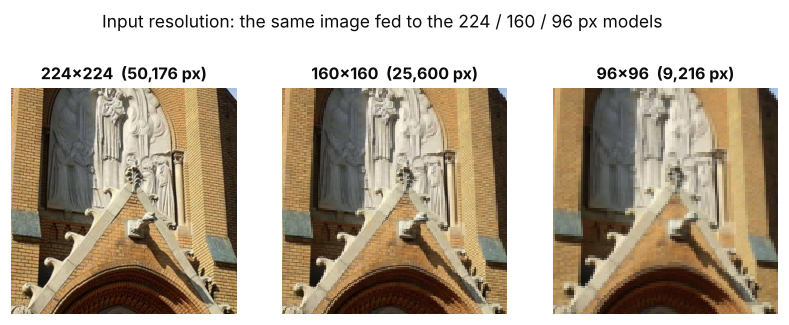

In [5]:
# What the network actually "sees" at each input size (same validation image, same display size)
example = int(np.flatnonzero(val_labels == WNID_TO_IDX["n03028079"])[7])   # a church
fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
for ax, res in zip(axes, RESOLUTIONS):
    ax.imshow(np.load(VAL_NPY[res], mmap_mode="r")[example], interpolation="nearest")
    ax.set_title(f"{res}x{res}  ({res * res:,} px)")
    ax.axis("off")
fig.suptitle("Input resolution: the same image fed to the 224 / 160 / 96 px models", y=1.02)
savefig(fig, "fig1_input_resolutions.png")
plt.show()

## 3. Pre-trained MobileNetV2

`tf.keras.applications.MobileNetV2` (width multiplier α = 1.0) provides ImageNet-pre-trained checkpoints trained
at 96, 128, 160, 192 and 224 px. For each input size the matching checkpoint is loaded; this is how MobileNetV2 is
meant to be used at reduced resolution. The architecture and the 3.5 M parameters are the same for all sizes,
but the compute cost scales with the number of pixels.

MobileNetV2 expects inputs in [-1, 1]. That scaling is a `Rescaling` layer **inside the graph**, so the deployed
model takes **raw RGB bytes (0–255)**. After full-integer conversion this means camera frames can be fed to the
model as `uint8` without any pre-processing on the device CPU.

In [6]:
def build_mobilenetv2(res):
    backbone = tf.keras.applications.MobileNetV2(input_shape=(res, res, 3), alpha=1.0,
                                                 include_top=True, weights="imagenet")
    inputs = tf.keras.Input((res, res, 3), name="rgb_0_255")
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1.0, name="to_minus1_plus1")(inputs)
    return tf.keras.Model(inputs, backbone(x), name=f"mobilenetv2_{res}")

KERAS = {res: build_mobilenetv2(res) for res in RESOLUTIONS}
pd.DataFrame([{"model": m.name, "input": f"{r}x{r}x3 (raw pixels)", "output": "1000-way softmax",
               "parameters": f"{m.count_params():,}", "layers in backbone": len(m.layers[-1].layers)}
              for r, m in KERAS.items()]).style.hide(axis="index")

model,input,output,parameters,layers in backbone
mobilenetv2_224,224x224x3 (raw pixels),1000-way softmax,"3,538,984",156
mobilenetv2_160,160x160x3 (raw pixels),1000-way softmax,"3,538,984",156
mobilenetv2_96,96x96x3 (raw pixels),1000-way softmax,"3,538,984",156


## 4. TFLite conversion with full-integer quantisation

Three converter configurations are produced for every resolution:

| variant | converter settings | purpose |
|---|---|---|
| `fp32` | no optimisation | float baseline |
| `int8_fallback` | `optimizations=[DEFAULT]` + `representative_dataset` | the *"integer with float fallback"* recipe: weights **and** activations INT8, but the converter may keep float kernels where no INT8 kernel exists; I/O stays float32 |
| `int8` | the above **+** `supported_ops=[TFLITE_BUILTINS_INT8]`, `inference_input_type=uint8`, `inference_output_type=uint8` | **full-integer, integer-only** model with uint8 camera input and uint8 scores: the deployment target |

**Calibration.** The `representative_dataset` generator gives the converter 300 real, pre-processed training
images, one at a time. The converter runs the float graph on them, records the min/max of every activation
tensor, and uses those ranges to choose each tensor's INT8 scale *s* and zero-point *z*
(real ≈ *s*·(q − *z*)). Weights are quantised **symmetrically per output channel** (*z* = 0, one scale per filter).
Biases are stored as **int32** with scale *s*<sub>input</sub>·*s*<sub>weight</sub>.

In [7]:
def representative_dataset(images):
    # Generator the converter calls to calibrate activation ranges: one image per step.
    def gen():
        for img in images:
            yield [img[None].astype(np.float32)]
    return gen

def convert(model, mode, calib_images=None):
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    if mode in ("int8", "int8_fallback"):
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = representative_dataset(calib_images)
    if mode == "int8":
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.uint8
        conv.inference_output_type = tf.uint8
    with quiet():                                            # silence SavedModel export chatter
        return conv.convert()

MODES = ["fp32", "int8_fallback", "int8"]
TFLITE, rows = {}, []
for res in RESOLUTIONS:
    for mode in MODES:
        t0 = time.perf_counter()
        blob = convert(KERAS[res], mode, CALIB[res])
        path = os.path.join(MODEL_DIR, f"mobilenetv2_{res}_{mode}.tflite")
        with open(path, "wb") as f:
            f.write(blob)
        TFLITE[(res, mode)] = path
        rows.append({"resolution": res, "variant": mode, "file": os.path.basename(path),
                     "size (MB)": len(blob) / 1e6, "conversion time (s)": time.perf_counter() - t0})
conv_df = pd.DataFrame(rows)
fp32_size = conv_df[conv_df.variant == "fp32"].set_index("resolution")["size (MB)"]
conv_df["compression vs FP32"] = conv_df.resolution.map(fp32_size) / conv_df["size (MB)"]
conv_df.style.hide(axis="index").format({"size (MB)": "{:.2f}", "conversion time (s)": "{:.1f}",
                                         "compression vs FP32": "{:.2f}x"})

resolution,variant,file,size (MB),conversion time (s),compression vs FP32
224,fp32,mobilenetv2_224_fp32.tflite,14.01,9.1,1.00x
224,int8_fallback,mobilenetv2_224_int8_fallback.tflite,4.04,40.2,3.47x
224,int8,mobilenetv2_224_int8.tflite,4.04,39.9,3.47x
160,fp32,mobilenetv2_160_fp32.tflite,14.01,9.2,1.00x
160,int8_fallback,mobilenetv2_160_int8_fallback.tflite,4.04,26.2,3.47x
160,int8,mobilenetv2_160_int8.tflite,4.04,26.2,3.47x
96,fp32,mobilenetv2_96_fp32.tflite,14.01,9.5,1.00x
96,int8_fallback,mobilenetv2_96_int8_fallback.tflite,4.04,16.2,3.47x
96,int8,mobilenetv2_96_int8.tflite,4.04,16.6,3.47x


**Sanity check.** Before going further, each TFLite model is compared with the original Keras model on 200
validation images. FP32 conversion should be numerically lossless. INT8 models should differ by quantisation noise
only.

In [8]:
def tflite_scores(path, images):
    # Run a .tflite model in-process; return de-quantised float scores.
    with quiet():
        it = Interpreter(model_path=path)
        it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    scores = []
    for img in images:
        it.set_tensor(inp["index"], img[None].astype(inp["dtype"]))
        it.invoke()
        y = it.get_tensor(out["index"])[0].astype(np.float32)
        if out["dtype"] != np.float32:
            s, z = out["quantization"]
            y = (y - z) * s
        scores.append(y)
    return np.stack(scores)

rows = []
for res in RESOLUTIONS:
    sample = np.asarray(np.load(VAL_NPY[res], mmap_mode="r")[::len(val_files) // 200][:200])
    ref = KERAS[res].predict(sample.astype(np.float32), verbose=0, batch_size=50)
    for mode in MODES:
        p = tflite_scores(TFLITE[(res, mode)], sample)
        rows.append({"resolution": res, "variant": mode,
                     "max |p_tflite - p_keras|": np.abs(p - ref).max(),
                     "top-1 agreement with Keras": (p.argmax(1) == ref.argmax(1)).mean()})
pd.DataFrame(rows).style.hide(axis="index").format({"max |p_tflite - p_keras|": "{:.2e}",
                                                    "top-1 agreement with Keras": "{:.1%}"})

resolution,variant,max |p_tflite - p_keras|,top-1 agreement with Keras
224,fp32,8.17e-06,100.0%
224,int8_fallback,8.22e-01,91.5%
224,int8,8.22e-01,91.5%
160,fp32,6.85e-06,100.0%
160,int8_fallback,3.97e-01,92.5%
160,int8,3.97e-01,92.5%
96,fp32,8.49e-06,100.0%
96,int8_fallback,8.55e-01,80.5%
96,int8,8.55e-01,80.5%


## 5. FlatBuffer inspection: which operators were quantised?

A `.tflite` file is a **FlatBuffer** with the following structure:
`Model → operator_codes[] , subgraphs[] → (tensors[], operators[]) , buffers[]`.
Every tensor records its **type** (`FLOAT32`, `INT8`, `UINT8`, `INT32`, …), its shape, its buffer (constant data
for weights) and its **quantisation parameters** (scale[], zero_point[], quantized_dimension). Every operator
points to an opcode and to its input/output tensor indices.

The file is parsed directly with the Python classes generated from the official TFLite schema
(`schema_py_generated`, shipped with TensorFlow). Each operator is classified as follows:

* **INT8 kernel**: every activation input and output is an integer type. This is an integer kernel.
* **float kernel**: an activation input or output is `FLOAT32`. In a quantised model this is a
  **float fallback**.
* **boundary**: a `QUANTIZE` (float→int) or `DEQUANTIZE` (int→float) op that the converter inserted to move
  between the integer and float domains.
* **integer requantize**: a `QUANTIZE` from one integer type to another (e.g. uint8 → int8), which is still
  integer arithmetic.

In [9]:
OPNAME = {v: k for k, v in vars(tflschema.BuiltinOperator).items() if not k.startswith("_")}
DTYPE = {v: k for k, v in vars(tflschema.TensorType).items() if not k.startswith("_")}
WEIGHTED_OPS = {"CONV_2D", "DEPTHWISE_CONV_2D", "FULLY_CONNECTED"}

def tensor_info(model, graph, idx):
    t = graph.Tensors(idx)
    buf = model.Buffers(t.Buffer())
    q = t.Quantization()
    has_q = q is not None and q.ScaleLength() > 0
    return {"name": t.Name().decode(), "dtype": DTYPE[t.Type()],
            "shape": tuple(int(s) for s in t.ShapeAsNumpy()) if t.ShapeLength() else (),
            "const": buf is not None and buf.DataLength() > 0,
            "nbytes": buf.DataLength() if buf is not None else 0,
            "scales": q.ScaleAsNumpy() if has_q else None,
            "zero_points": q.ZeroPointAsNumpy() if has_q and q.ZeroPointLength() else None}

def op_macs(op, ins, outs):
    # Multiply-accumulates for the compute-heavy ops (weights layout as stored in TFLite).
    n_out = int(np.prod(outs[0]["shape"]))
    w = ins[1]["shape"] if len(ins) > 1 else None
    if op == "CONV_2D":            return n_out * w[1] * w[2] * w[3]     # [Cout, kh, kw, Cin]
    if op == "DEPTHWISE_CONV_2D":  return n_out * w[1] * w[2]            # [1, kh, kw, C]
    if op == "FULLY_CONNECTED":    return n_out * w[1]                   # [out, in]
    return 0

def classify(op, acts, outs):
    if op == "QUANTIZE":
        return "boundary float→int" if acts[0]["dtype"].startswith("FLOAT") else "integer requantize"
    if op == "DEQUANTIZE":
        return "boundary int→float"
    if any(t["dtype"].startswith("FLOAT") for t in acts + outs):
        return "float kernel"
    return "INT8 kernel"

def quant_desc(t):
    if t is None: return ""
    if t["scales"] is None: return "none"
    return f"per-channel ({len(t['scales'])})" if len(t["scales"]) > 1 else "per-tensor"

def inspect_tflite(model_bytes_or_path):
    # Parse a .tflite FlatBuffer into a per-operator DataFrame.
    buf = model_bytes_or_path
    if isinstance(buf, str):
        with open(buf, "rb") as f:
            buf = f.read()
    model = tflschema.Model.GetRootAsModel(buf, 0)
    graph = model.Subgraphs(0)
    rows = []
    for i in range(graph.OperatorsLength()):
        o = graph.Operators(i)
        code = model.OperatorCodes(o.OpcodeIndex())
        op = OPNAME.get(max(code.BuiltinCode(), code.DeprecatedBuiltinCode()), "CUSTOM")
        ins = [tensor_info(model, graph, j) for j in o.InputsAsNumpy() if j >= 0]
        outs = [tensor_info(model, graph, j) for j in o.OutputsAsNumpy()]
        acts = [t for t in ins if not t["const"]] or ins[:1]
        consts = [t for t in ins if t["const"]]
        weight = consts[0] if op in WEIGHTED_OPS and consts else None
        bias = consts[1] if op in WEIGHTED_OPS and len(consts) > 1 else None
        rows.append({"idx": i, "op": op,
                     "input dtype": acts[0]["dtype"], "weight dtype": weight["dtype"] if weight else "",
                     "weight quant": quant_desc(weight), "bias dtype": bias["dtype"] if bias else "",
                     "output dtype": outs[0]["dtype"],
                     "out scale": float(outs[0]["scales"][0]) if outs[0]["scales"] is not None else np.nan,
                     "out zero-point": int(outs[0]["zero_points"][0])
                                       if outs[0]["zero_points"] is not None else np.nan,
                     "MACs": op_macs(op, ins, outs), "status": classify(op, acts, outs),
                     "output tensor": outs[0]["name"][-60:], "_ins": ins, "_outs": outs})
    df = pd.DataFrame(rows).set_index("idx")
    tensors = [tensor_info(model, graph, j) for j in range(graph.TensorsLength())]
    return df, tensors

OPS = {key: inspect_tflite(path) for key, path in TFLITE.items()}
ops224, tensors224 = OPS[(224, "int8")]
print(f"mobilenetv2_224_int8.tflite: {len(ops224)} operators, {len(tensors224)} tensors")
ops224.drop(columns=["_ins", "_outs", "output tensor"]).head(12)

mobilenetv2_224_int8.tflite: 69 operators, 179 tensors


,op,input dtype,weight dtype,weight quant,bias dtype,output dtype,out scale,out zero-point,MACs,status
idx,,,,,,,,,,
0,QUANTIZE,UINT8,,,,INT8,1.000000,-128,0,integer requantize
1,MUL,INT8,,,,INT8,0.011765,-43,0,INT8 kernel
2,ADD,INT8,,,,INT8,0.007843,-1,0,INT8 kernel
3,CONV_2D,INT8,INT8,per-channel (32),INT32,INT8,0.023529,-128,10838016,INT8 kernel
4,DEPTHWISE_CONV_2D,INT8,INT8,per-channel (32),INT32,INT8,0.023529,-128,3612672,INT8 kernel
5,CONV_2D,INT8,INT8,per-channel (16),INT32,INT8,0.333602,1,6422528,INT8 kernel
6,CONV_2D,INT8,INT8,per-channel (96),INT32,INT8,0.023529,-128,19267584,INT8 kernel
7,DEPTHWISE_CONV_2D,INT8,INT8,per-channel (96),INT32,INT8,0.023529,-128,2709504,INT8 kernel
8,CONV_2D,INT8,INT8,per-channel (24),INT32,INT8,0.268425,-12,7225344,INT8 kernel


### 5.1 Operator-type summary of the deployed INT8 model (224 px)

In [10]:
def no_count(quant):
    return re.sub(r" \(\d+\)", "", quant)          # "per-channel (32)" -> "per-channel"

def op_type_table(df):
    g = df.groupby("op", sort=False)
    t = pd.DataFrame({
        "count": g.size(),
        "input dtype": g["input dtype"].agg(lambda s: "/".join(sorted(set(s)))),
        "weights": g.apply(lambda d: "/".join(sorted({f"{a} {no_count(b)}" for a, b in
                                                      zip(d["weight dtype"], d["weight quant"]) if a}))),
        "bias": g["bias dtype"].agg(lambda s: "/".join(sorted(set(s) - {""}))),
        "output dtype": g["output dtype"].agg(lambda s: "/".join(sorted(set(s)))),
        "share of MACs": g["MACs"].sum() / df["MACs"].sum(),
        "status": g["status"].agg(lambda s: "/".join(sorted(set(s)))),
    })
    return t.sort_values("count", ascending=False)

op_table_224 = op_type_table(ops224)
op_table_224.to_csv(os.path.join(RESULT_DIR, "flatbuffer_op_types_int8_224.csv"))
ops224.drop(columns=["_ins", "_outs"]).to_csv(os.path.join(RESULT_DIR, "flatbuffer_ops_int8_224.csv"))
op_table_224.style.format({"share of MACs": "{:.1%}"})

,count,input dtype,weights,bias,output dtype,share of MACs,status
op,,,,,,,
CONV_2D,35,INT8,INT8 per-channel,INT32,INT8,92.7%,INT8 kernel
DEPTHWISE_CONV_2D,17,INT8,INT8 per-channel,INT32,INT8,6.9%,INT8 kernel
ADD,11,INT8,,,INT8,0.0%,INT8 kernel
QUANTIZE,2,INT8/UINT8,,,INT8/UINT8,0.0%,integer requantize
MUL,1,INT8,,,INT8,0.0%,INT8 kernel
MEAN,1,INT8,,,INT8,0.0%,INT8 kernel
FULLY_CONNECTED,1,INT8,INT8 per-channel,INT32,INT8,0.4%,INT8 kernel
SOFTMAX,1,INT8,,,INT8,0.0%,INT8 kernel


### 5.2 Quantisation parameters read from the FlatBuffer

In [11]:
first_q = ops224.iloc[0]                                   # QUANTIZE uint8 -> int8
conv1 = ops224[ops224.op == "CONV_2D"].iloc[0]             # first convolution
w, b = [t for t in conv1["_ins"] if t["const"]]
x_in = [t for t in conv1["_ins"] if not t["const"]][0]
expected_bias_scale = x_in["scales"][0] * w["scales"]
dw = ops224[ops224.op == "DEPTHWISE_CONV_2D"].iloc[0]
softmax = ops224[ops224.op == "SOFTMAX"].iloc[0]
last = ops224.iloc[-1]

facts = [
    ("model input", f"{first_q['_ins'][0]['dtype']}  scale={first_q['_ins'][0]['scales'][0]:.4g}  "
                    f"zp={first_q['_ins'][0]['zero_points'][0]}  -> a camera byte is fed in unchanged"),
    ("after input QUANTIZE", f"{first_q['output dtype']}  scale={first_q['out scale']:.4g}  "
                             f"zp={first_q['out zero-point']:.0f}  (integer re-centring 0..255 -> -128..127)"),
    ("Conv1 weights", f"{w['dtype']} {w['shape']}  {len(w['scales'])} per-channel scales "
                      f"[{w['scales'].min():.2e} .. {w['scales'].max():.2e}]  zero-points all "
                      f"{set(w['zero_points'].tolist())}  -> symmetric"),
    ("Conv1 bias", f"{b['dtype']}  scale = s_in * s_w  (max relative error "
                   f"{np.max(np.abs(b['scales'] - expected_bias_scale) / expected_bias_scale):.1e})"),
    ("Conv1 output (fused ReLU6)", f"{conv1['output dtype']}  scale={conv1['out scale']:.5f} "
                                   f"(6/255={6 / 255:.5f})  zp={conv1['out zero-point']:.0f}  -> range [0, 6]"),
    ("1st depthwise weights", f"{dw['weight dtype']}  {dw['weight quant']}"),
    ("SOFTMAX output", f"{softmax['output dtype']}  scale={softmax['out scale']:.6f} (1/256)  "
                       f"zp={softmax['out zero-point']:.0f}"),
    ("model output", f"{last['output dtype']}  scale={last['out scale']:.6f}  zp={last['out zero-point']:.0f}"),
]
pd.DataFrame(facts, columns=["tensor", "what the FlatBuffer stores"]).style.hide(axis="index")

tensor,what the FlatBuffer stores
model input,UINT8 scale=1 zp=0 -> a camera byte is fed in unchanged
after input QUANTIZE,INT8 scale=1 zp=-128 (integer re-centring 0..255 -> -128..127)
Conv1 weights,"INT8 (32, 3, 3, 3) 32 per-channel scales [1.04e-08 .. 2.86e-02] zero-points all {0} -> symmetric"
Conv1 bias,INT32 scale = s_in * s_w (max relative error 0.0e+00)
Conv1 output (fused ReLU6),"INT8 scale=0.02353 (6/255=0.02353) zp=-128 -> range [0, 6]"
1st depthwise weights,INT8 per-channel (32)
SOFTMAX output,INT8 scale=0.003906 (1/256) zp=-128
model output,UINT8 scale=0.003906 zp=0


### 5.3 All variants side by side

In [12]:
def weight_storage(tensors):
    by = {}
    for t in tensors:
        if t["const"]:
            by[t["dtype"]] = by.get(t["dtype"], 0) + t["nbytes"]
    fmt = lambda v: f"{v / 1e6:.2f} MB" if v > 1e5 else f"{v / 1e3:.0f} kB" if v > 1e3 else f"{v} B"
    return ", ".join(f"{k} {fmt(v)}" for k, v in sorted(by.items(), key=lambda kv: -kv[1]))

def first_float_coverage(df):
    # Share of MACs that come *before* the first float kernel, i.e. what a single-partition
    # integer-only accelerator (e.g. Edge TPU) could execute before handing the rest to the CPU.
    is_float = (df.status == "float kernel").to_numpy()
    if not is_float.any():
        return 1.0
    return df["MACs"].to_numpy()[:np.argmax(is_float)].sum() / df["MACs"].sum()

def variant_summary(key, df, tensors):
    s = df.status.value_counts()
    int_macs = df.loc[df.status == "INT8 kernel", "MACs"].sum() / df["MACs"].sum()
    return {"model": f"mobilenetv2_{key[0]}_{key[1]}", "operators": len(df),
            "INT8 kernels": s.get("INT8 kernel", 0), "float kernels": s.get("float kernel", 0),
            "QUANTIZE/DEQUANTIZE boundaries": s.get("boundary float→int", 0) + s.get("boundary int→float", 0),
            "int requantize": s.get("integer requantize", 0),
            "MACs on INT8 kernels": int_macs, "MACs before 1st float op": first_float_coverage(df),
            "I/O dtype": f"{df.iloc[0]['input dtype']} -> {df.iloc[-1]['output dtype']}",
            "constant (weight) storage": weight_storage(tensors), "GMACs": df["MACs"].sum() / 1e9}

def show_variants(df):
    short = {"QUANTIZE/DEQUANTIZE boundaries": "Q/DQ bound-aries", "int requantize": "int requant.",
             "MACs on INT8 kernels": "MACs on INT8", "MACs before 1st float op": "MACs before 1st float op",
             "constant (weight) storage": "weights stored as"}
    return df.drop(columns=["GMACs"]).rename(columns=short).style.hide(axis="index").format(
        {"MACs on INT8": "{:.0%}", "MACs before 1st float op": "{:.0%}"})

variants_df = pd.DataFrame([variant_summary(k, *OPS[k]) for k in TFLITE])
variants_df.to_csv(os.path.join(RESULT_DIR, "flatbuffer_variant_summary.csv"), index=False)
show_variants(variants_df)

model,operators,INT8 kernels,float kernels,Q/DQ bound-aries,int requant.,MACs on INT8,MACs before 1st float op,I/O dtype,weights stored as
mobilenetv2_224_fp32,67,0,67,0,0,0%,0%,FLOAT32 -> FLOAT32,"FLOAT32 13.95 MB, INT32 8 B"
mobilenetv2_224_int8_fallback,69,67,0,2,0,100%,100%,FLOAT32 -> FLOAT32,"INT8 3.47 MB, INT32 72 kB"
mobilenetv2_224_int8,69,67,0,0,2,100%,100%,UINT8 -> UINT8,"INT8 3.47 MB, INT32 72 kB"
mobilenetv2_160_fp32,67,0,67,0,0,0%,0%,FLOAT32 -> FLOAT32,"FLOAT32 13.95 MB, INT32 8 B"
mobilenetv2_160_int8_fallback,69,67,0,2,0,100%,100%,FLOAT32 -> FLOAT32,"INT8 3.47 MB, INT32 72 kB"
mobilenetv2_160_int8,69,67,0,0,2,100%,100%,UINT8 -> UINT8,"INT8 3.47 MB, INT32 72 kB"
mobilenetv2_96_fp32,67,0,67,0,0,0%,0%,FLOAT32 -> FLOAT32,"FLOAT32 13.95 MB, INT32 8 B"
mobilenetv2_96_int8_fallback,69,67,0,2,0,100%,100%,FLOAT32 -> FLOAT32,"INT8 3.47 MB, INT32 72 kB"
mobilenetv2_96_int8,69,67,0,0,2,100%,100%,UINT8 -> UINT8,"INT8 3.47 MB, INT32 72 kB"


In [13]:
# Where are the float tensors in the 'float fallback allowed' variant?
fb = OPS[(224, "int8_fallback")][0]
print("int8_fallback, 224 px: non-INT8 operators")
fb[fb.status != "INT8 kernel"][["op", "input dtype", "output dtype", "status"]]

int8_fallback, 224 px: non-INT8 operators


,op,input dtype,output dtype,status
idx,,,,
0,QUANTIZE,FLOAT32,INT8,boundary float→int
68,DEQUANTIZE,INT8,FLOAT32,boundary int→float


**What the inspection shows.**

* In the integer-only `int8` models, **every compute operator** of MobileNetV2 runs on an **INT8 kernel**:
  `CONV_2D`, `DEPTHWISE_CONV_2D`, `ADD` (the 10 residual connections), `MEAN` (global average pooling),
  `FULLY_CONNECTED`, `SOFTMAX`, and the `MUL`/`ADD` of the in-graph rescaling. ReLU6 has no operator of its own
  because it is **fused** into the convolutions as a clamp of the int8 output range (scale = 6/255). Weights are
  int8 with per-channel scales, biases int32, and activations int8 with per-tensor scale and zero-point. The only
  other ops are the two integer requantisations at the edges (uint8 camera bytes → int8, int8 scores → uint8).
  **No operator needed a float fallback**, and 100 % of the MACs run in integer arithmetic.
* The `int8_fallback` variant has exactly the same INT8 interior. Its only float parts are the **I/O boundaries**:
  a `QUANTIZE` (float→int8) at the input and a `DEQUANTIZE` (int8→float) at the output, added because the I/O
  type was left as float32.
* The `fp32` model has the same graph topology, but every kernel is float and the weights take ~14 MB instead of
  ~3.5 MB.

MobileNetV2 was designed with integer inference in mind (ReLU6 bounds every activation, there are no exotic
non-linearities, and batch-norm folds into the convolutions), so it quantises cleanly. The next two subsections
show what happens when a model contains an operator **without** an INT8 kernel.

### 5.4 Operator-coverage probe: which TFLite ops have an INT8 kernel?

The same full-integer recipe (`TFLITE_BUILTINS_INT8`, int8 I/O, representative data) is applied to a tiny model
`Dense → <op> → Dense` for a range of common operations. The FlatBuffer is then inspected to see whether the op
got an INT8 kernel or was left in float between a `DEQUANTIZE` and a `QUANTIZE`.

In [14]:
PROBE_OPS = {
    "relu6":                 lambda x: tf.nn.relu6(x),
    "hard-swish":            lambda x: x * tf.nn.relu6(x + 3.0) / 6.0,
    "sigmoid":               tf.nn.sigmoid,
    "tanh":                  tf.nn.tanh,
    "exp":                   tf.math.exp,
    "log":                   lambda x: tf.math.log(tf.nn.relu(x) + 1.0),
    "sqrt":                  lambda x: tf.math.sqrt(tf.nn.relu(x) + 1.0),
    "rsqrt":                 lambda x: tf.math.rsqrt(tf.nn.relu(x) + 1.0),
    "gelu (tf.nn.gelu)":     lambda x: tf.nn.gelu(x),
    "l2_normalize":          lambda x: tf.math.l2_normalize(x, axis=-1),
    "divide (tensor/tensor)": lambda x: x / (tf.nn.relu(x) + 1.0),
    "squared_difference":    lambda x: tf.math.squared_difference(x, 0.5),
    "square":                tf.math.square,
    "pow (x^1.5)":           lambda x: tf.math.pow(tf.nn.relu(x) + 1.0, 1.5),
    "sin":                   tf.math.sin,
    "cos":                   tf.math.cos,
    "floor":                 tf.math.floor,
    "round":                 tf.math.round,
    "sign":                  tf.math.sign,
    "elu":                   tf.nn.elu,
    "cumsum":                lambda x: tf.math.cumsum(x, axis=-1),
    "atan2":                 lambda x: tf.math.atan2(x, tf.nn.relu(x) + 1.0),
    "erf":                   tf.math.erf,
}

def probe(fn):
    inp = tf.keras.Input((16,))
    h = tf.keras.layers.Dense(16)(inp)
    m = tf.keras.Model(inp, tf.keras.layers.Dense(4)(tf.keras.layers.Lambda(fn)(h)))
    conv = tf.lite.TFLiteConverter.from_keras_model(m)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = lambda: ([np.random.randn(1, 16).astype(np.float32)] for _ in range(32))
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = conv.inference_output_type = tf.int8
    try:
        with quiet():
            blob = conv.convert()
    except Exception as e:
        msg = str(e)
        reason = "not a TFLite builtin op" if "not supported" in msg or "Flex" in msg or "MLIR" in msg else msg
        return {"TFLite op(s) emitted": "—", "kernel": "conversion FAILED", "converter raised an error?":
                f"yes ({reason})"}
    df, _ = inspect_tflite(blob)
    core = df[(df.op != "FULLY_CONNECTED") & ~df.status.str.startswith(("boundary", "integer"))]
    float_ops = core[core.status == "float kernel"]
    return {"TFLite op(s) emitted": " ".join(core.op) or "(fused into FULLY_CONNECTED)",
            "kernel": "FLOAT fallback" if len(float_ops) else "INT8",
            "converter raised an error?": "no"}

probe_df = pd.DataFrame([{"TensorFlow op": name, **probe(fn)} for name, fn in PROBE_OPS.items()])
probe_df.to_csv(os.path.join(RESULT_DIR, "op_int8_probe.csv"), index=False)
probe_df.style.hide(axis="index").map(
    lambda v: "color:#b4441c;font-weight:600" if v in ("FLOAT fallback", "conversion FAILED") else "",
    subset=["kernel"])

TensorFlow op,TFLite op(s) emitted,kernel,converter raised an error?
relu6,(fused into FULLY_CONNECTED),INT8,no
hard-swish,HARD_SWISH,INT8,no
sigmoid,LOGISTIC,INT8,no
tanh,TANH,INT8,no
exp,EXP,INT8,no
log,ADD LOG,INT8,no
sqrt,ADD SQRT,INT8,no
rsqrt,ADD RSQRT,INT8,no
gelu (tf.nn.gelu),GELU,INT8,no
l2_normalize,L2_NORMALIZATION,INT8,no


Three findings come out of the probe:

1. **INT8 coverage is a property of each kernel.** Bounded, monotonic functions such as sigmoid, tanh,
   hard-swish, exp, log, sqrt and gelu have INT8 kernels. These are usually implemented as 256-entry lookup tables
   or fixed-point approximations. `square`, `pow`, `sin`, `cos`, `floor`, `round`, `sign`, `elu`, `cumsum` and
   `atan2` have **no INT8 kernel** in this TFLite version. The converter keeps them in float and wraps each one in
   `DEQUANTIZE → op(float) → QUANTIZE`. Some of these gaps are engineering priorities, not mathematical limits:
   `square(x)` is just `mul(x, x)`, and `MUL` *does* have an INT8 kernel.
2. **`TFLITE_BUILTINS_INT8` did not stop it.** Even with the integer-only op set and int8 I/O requested, the
   converter (TF 2.21) emitted float islands **without raising an error**. "Full-integer" in the converter settings
   therefore does not guarantee an integer-only model, and the FlatBuffer has to be inspected (as in Section 5) to
   know what will actually run.
3. **`erf` is not a TFLite builtin at all.** Conversion fails unless `SELECT_TF_OPS` (Flex delegate) is enabled.
   That links a large part of the TensorFlow runtime into the app and always runs in float.

### 5.5 Case study model: one float-only op inside MobileNetV2

A realistic reason for a float op inside an edge model is **in-graph pre-processing**. Suppose the camera sensor
delivers **linear-light** RGB (no ISP gamma curve). MobileNetV2 was trained on gamma-encoded sRGB JPEGs, so the
deployment graph must re-apply the gamma curve *x*<sup>1/2.2</sup> before the usual [-1, 1] scaling. The linear
sensor is simulated by applying *x*<sup>2.2</sup> to the uint8 test and calibration images (and re-quantising to
uint8, as a real 8-bit linear sensor would). Two implementations of the same curve are compared:

* **`pow`**: `tf.pow(x, 1/2.2)`. Section 5.4 showed that `POW` has **no INT8 kernel**.
* **`explog`**: the same curve built from ops that *do* have INT8 kernels, *x*<sup>1/γ</sup> = exp(log *x* / γ)
  (with a small ε and a re-normalisation so that 0→0 and 1→1). This is the "rewrite the op" mitigation.

Both are converted with exactly the same full-integer recipe as the main models.

In [15]:
GAMMA, EPS = 2.2, 2e-3
_LIN_LUT = np.clip(np.round(255.0 * (np.arange(256) / 255.0) ** GAMMA), 0, 255).astype(np.uint8)
_LO, _HI = EPS ** (1 / GAMMA), (1 + EPS) ** (1 / GAMMA)

def to_linear_light(img_u8):
    # Simulate an 8-bit linear-light sensor from an sRGB uint8 image.
    return _LIN_LUT[img_u8]

GAMMA_IMPL = {
    "pow":    lambda v: tf.pow(v / 255.0 + 1e-6, 1.0 / GAMMA),                         # POW: float only
    "explog": lambda v: (tf.exp(tf.math.log(v / 255.0 + EPS) / GAMMA) - _LO) / (_HI - _LO),  # LOG/EXP: INT8
}

def build_linear_camera_model(res, impl):
    backbone = KERAS[res].layers[-1]                                   # same pre-trained weights
    inputs = tf.keras.Input((res, res, 3), name="linear_rgb_0_255")
    x = tf.keras.layers.Lambda(GAMMA_IMPL[impl], name=f"gamma_{impl}")(inputs)   # sRGB-like, in [0, 1]
    x = tf.keras.layers.Rescaling(2.0, offset=-1.0, name="to_minus1_plus1")(x)
    return tf.keras.Model(inputs, backbone(x), name=f"mobilenetv2_{res}_linear_{impl}")

CASE_RES = 224
VAL_LINEAR_NPY = os.path.join(DATA_DIR, f"val_linear_{CASE_RES}.npy")
if not os.path.exists(VAL_LINEAR_NPY):
    np.save(VAL_LINEAR_NPY, to_linear_light(np.load(VAL_NPY[CASE_RES])))
calib_linear = to_linear_light(CALIB[CASE_RES])

CASE_KEYS = []
for impl in GAMMA_IMPL:
    model = build_linear_camera_model(CASE_RES, impl)
    for mode in ("fp32", "int8"):
        key = (f"{CASE_RES}-linear-{impl}", mode)
        TFLITE[key] = os.path.join(MODEL_DIR, f"mobilenetv2_{CASE_RES}_linear_{impl}_{mode}.tflite")
        with open(TFLITE[key], "wb") as f:
            f.write(convert(model, mode, calib_linear))
        OPS[key] = inspect_tflite(TFLITE[key])
        CASE_KEYS.append(key)

show = ["op", "input dtype", "output dtype", "status"]
first_ops = pd.concat({impl: OPS[(f"{CASE_RES}-linear-{impl}", "int8")][0][show].head(9).reset_index(drop=True)
                       for impl in GAMMA_IMPL}, axis=1)
first_ops.index.name = "op #"
first_ops

pow                                                 explog  \
              op input dtype output dtype              status        op   
op #                                                                      
0       QUANTIZE       UINT8         INT8  integer requantize  QUANTIZE   
1            MUL        INT8         INT8         INT8 kernel       MUL   
2            ADD        INT8         INT8         INT8 kernel       ADD   
3     DEQUANTIZE        INT8      FLOAT32  boundary int→float       LOG   
4            POW     FLOAT32      FLOAT32        float kernel       MUL   
5       QUANTIZE     FLOAT32         INT8  boundary float→int       EXP   
6            MUL        INT8         INT8         INT8 kernel       SUB   
7            ADD        INT8         INT8         INT8 kernel       MUL   
8        CONV_2D        INT8         INT8         INT8 kernel       MUL   

                                                   
     input dtype output dtype              status  
op #                                               
0          UINT8         INT8  integer requantize  
1           INT8         INT8         INT8 kernel  
2           INT8         INT8         INT8 kernel  
3           INT8         INT8         INT8 kernel  
4           INT8         INT8         INT8 kernel  
5           INT8         INT8         INT8 kernel  
6           INT8         INT8         INT8 kernel  
7           INT8         INT8         INT8 kernel  
8           INT8         INT8         INT8 kernel

In [16]:
show_variants(pd.DataFrame([variant_summary(k, *OPS[k])
                            for k in [(CASE_RES, "int8")] + [k for k in CASE_KEYS if k[1] == "int8"]]))

model,operators,INT8 kernels,float kernels,Q/DQ bound-aries,int requant.,MACs on INT8,MACs before 1st float op,I/O dtype,weights stored as
mobilenetv2_224_int8,69,67,0,0,2,100%,100%,UINT8 -> UINT8,"INT8 3.47 MB, INT32 72 kB"
mobilenetv2_224-linear-pow_int8,74,69,1,2,2,100%,0%,UINT8 -> UINT8,"INT8 3.47 MB, INT32 72 kB, FLOAT32 4 B"
mobilenetv2_224-linear-explog_int8,76,74,0,0,2,100%,100%,UINT8 -> UINT8,"INT8 3.47 MB, INT32 72 kB"


In the **`pow`** model the FlatBuffer contains a float island right at the start of the graph:
`QUANTIZE(uint8→int8) → MUL → ADD → DEQUANTIZE → POW (float32) → QUANTIZE → …`. Everything after the island is
INT8 again, so on the CPU 100 % of the MACs still use integer kernels. An integer-only accelerator compiled into
a single partition (the documented behaviour of the Coral Edge TPU compiler) is different: every op from the first
unsupported one onwards runs on the CPU, so the share of MACs it could accelerate falls from **100 % to 0 %**.

The **`explog`** rewrite computes the same curve with `LOG`, `MUL`, `EXP` and `SUB`, which all have INT8 kernels.
The model is integer-only again, with 100 % accelerator coverage. Sections 8, 9 and 11 measure what each version
costs in latency and accuracy.

## 6. Per-layer quantisation error (TFLite Quantization Debugger)

Even when every op *has* an INT8 kernel, each layer adds rounding error. `tf.lite.experimental.QuantizationDebugger`
runs 64 held-out images through the quantised model and compares the output of every quantised op with its float
counterpart. Normalising the RMSE by the tensor's scale (one quantisation step) makes layers comparable.
Pure rounding of a uniform signal would give **1/√12 ≈ 0.29 steps**. Values well above that mean error is being
amplified or accumulated.

In [17]:
dbg_conv = tf.lite.TFLiteConverter.from_keras_model(KERAS[224])
dbg_conv.optimizations = [tf.lite.Optimize.DEFAULT]
dbg_conv.representative_dataset = representative_dataset(CALIB[224])
debug_images = np.asarray(np.load(VAL_NPY[224], mmap_mode="r")[7::61][:64])
with quiet():
    debugger = tf.lite.experimental.QuantizationDebugger(converter=dbg_conv,
                                                         debug_dataset=representative_dataset(debug_images))
    debugger.run()
buf = io.StringIO()
debugger.layer_statistics_dump(buf)
qstats = pd.read_csv(io.StringIO(buf.getvalue()))
qstats["rmse / scale"] = np.sqrt(qstats["mean_squared_error"]) / qstats["scale"]
qstats["layer"] = qstats["tensor_name"].str.extract(r"mobilenetv2_1\.00_224(?:_\d+)?/([^/;]+?)(?:_\d+)?/")[0]
qstats["depth"] = np.arange(len(qstats))
qstats.to_csv(os.path.join(RESULT_DIR, "quant_debugger_224.csv"), index=False)

print(qstats.groupby("op_name")["rmse / scale"].agg(["count", "mean", "max"]).round(3).to_string())
qstats.nlargest(8, "rmse / scale")[["depth", "op_name", "layer", "scale", "rmse / scale", "max_abs_error"]]

                   count   mean    max
op_name                               
ADD                   11  0.289  0.296
CONV_2D               35  0.336  0.540
DEPTHWISE_CONV_2D     17  0.406  1.400
FULLY_CONNECTED        1  0.301  0.301
MEAN                   1  0.239  0.239
MUL                    1  0.269  0.269
SOFTMAX                1  0.068  0.068


,depth,op_name,layer,scale,rmse / scale,max_abs_error
3,3,DEPTHWISE_CONV_2D,expanded_conv_depthwise_relu,0.023529,1.399594,0.154923
9,9,DEPTHWISE_CONV_2D,block_2_depthwise_relu,0.023529,0.724215,0.167659
20,20,DEPTHWISE_CONV_2D,block_5_depthwise_relu,0.023529,0.625424,0.321334
63,63,CONV_2D,out_relu,0.023529,0.539622,0.179758
51,51,CONV_2D,block_13_project_BN,0.135863,0.518222,0.324508
6,6,DEPTHWISE_CONV_2D,block_1_depthwise_relu,0.023529,0.449271,0.087528
2,2,CONV_2D,Conv1_relu,0.023529,0.445427,0.073834
39,39,DEPTHWISE_CONV_2D,block_10_depthwise_relu,0.023529,0.427491,0.088878


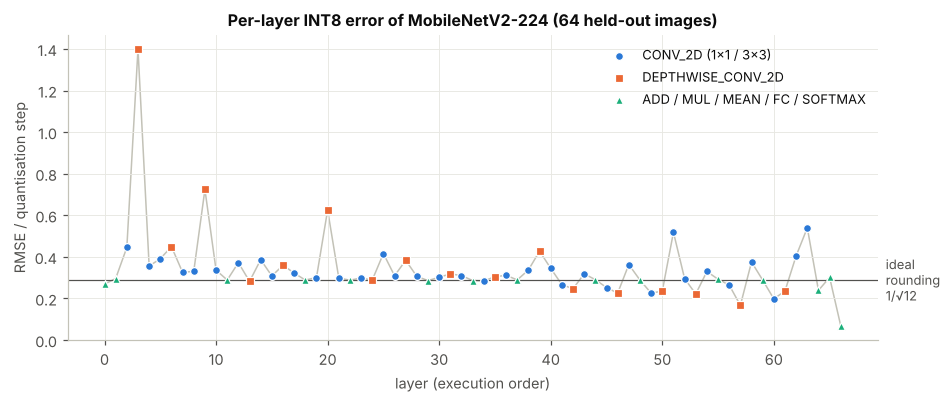

In [18]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(qstats["depth"], qstats["rmse / scale"], color="#c3c2b7", lw=1, zorder=1)
groups = [("CONV_2D", COLOR["fp32"], "o", "CONV_2D (1x1 / 3x3)"),
          ("DEPTHWISE_CONV_2D", COLOR["int8"], "s", "DEPTHWISE_CONV_2D"),
          (None, COLOR["linear"], "^", "ADD / MUL / MEAN / FC / SOFTMAX")]
for op, c, m, lab in groups:
    sel = qstats[qstats.op_name == op] if op else qstats[~qstats.op_name.isin(["CONV_2D", "DEPTHWISE_CONV_2D"])]
    ax.scatter(sel["depth"], sel["rmse / scale"], s=26, color=c, marker=m, label=lab,
               edgecolor="white", linewidth=0.8, zorder=3)
ax.axhline(1 / np.sqrt(12), color=INK2, lw=0.8)
ax.text(1.01, 1 / np.sqrt(12), "ideal\nrounding\n1/√12", transform=ax.get_yaxis_transform(),
        va="center", ha="left", color=INK2, fontsize=8.5)
ax.set_xlabel("layer (execution order)")
ax.set_ylabel("RMSE / quantisation step")
ax.set_title("Per-layer INT8 error of MobileNetV2-224 (64 held-out images)")
ax.legend(loc="upper right", ncol=1, fontsize=8.5)
ax.set_ylim(bottom=0)
savefig(fig, "fig2_per_layer_quant_error.png")
plt.show()

## 7. Simulated edge device: 256 MB RAM, 1 CPU core

The device is emulated with **Linux control groups**, the same kernel mechanism Docker's `--memory=256m --cpus=1`
uses. Every on-device run is a **fresh process** started inside a new cgroup:

| constraint | mechanism | effect |
|---|---|---|
| **256 MB RAM** | memory cgroup `memory.limit_in_bytes = 256 MiB` (swap limit equal, so no swap) | the kernel **OOM-kills** the process if it needs more |
| **1 CPU core** | cpu cgroup CFS quota = 100 ms per 100 ms period, **plus** cpuset/`taskset` pinning to core 0 | at most one core of CPU time, always on the same core |
| single-threaded inference | `Interpreter(num_threads=1)`, `OMP/OPENBLAS_NUM_THREADS=1` | no hidden thread pools |
| device software | only `numpy` + `ai_edge_litert` are imported | no full TensorFlow on the device |

If cgroups are not writable (e.g. an unprivileged notebook host), the sandbox falls back to CPU pinning only and
labels the results as *not enforced*.

The program that runs on the device is written to `edge_device_worker.py` by the next cell.

In [19]:
%%writefile edge_device_worker.py
"""edge_device_worker.py - the program that runs *inside* the simulated edge device.

The notebook launches this script in a sandbox limited to 256 MB of RAM and one
CPU core. Only NumPy and the stand-alone LiteRT runtime (``ai_edge_litert``) are
imported: full TensorFlow is never loaded on the "device", exactly as on a real
board where only the TFLite/LiteRT interpreter is installed.

Usage
-----
  python edge_device_worker.py bench <model.tflite> <image.npy> <n_warmup> <n_runs>
  python edge_device_worker.py eval  <model.tflite> <images.npy> <labels.npy>
  python edge_device_worker.py alloc <megabytes>            # sandbox self-test

Each mode prints a single JSON line on stdout.
"""
import json
import os
import resource
import sys
import time


def proc_status(key):
    """Read a field such as VmRSS / VmHWM (peak RSS) from /proc/self/status, in bytes."""
    with open("/proc/self/status") as f:
        for line in f:
            if line.startswith(key + ":"):
                return int(line.split()[1]) * 1024
    return None


def device_info():
    return {
        "cpu_affinity": sorted(os.sched_getaffinity(0)),
        "os_threads": len(os.listdir("/proc/self/task")),
        "pid": os.getpid(),
    }


if sys.argv[1] == "alloc":
    # Self-test: try to allocate more memory than the device has.
    mb = int(sys.argv[2])
    block = bytearray(b"\x01") * (mb * 2**20)   # every page is written, so it is really resident
    print(json.dumps({"allocated_mb": mb, "peak_rss": proc_status("VmHWM")}))
    sys.exit(0)

import numpy as np                                   # noqa: E402
from ai_edge_litert.interpreter import Interpreter   # noqa: E402

RSS_RUNTIME = proc_status("VmRSS")   # Python + NumPy + LiteRT, before any model is loaded


def load_interpreter(path):
    t0 = time.perf_counter()
    interp = Interpreter(model_path=path, num_threads=1)
    interp.allocate_tensors()
    return interp, (time.perf_counter() - t0) * 1e3


def to_model_input(pixels_uint8, inp):
    """Raw RGB pixels (0..255) -> whatever dtype the model's input tensor expects."""
    if inp["dtype"] == np.uint8:
        return pixels_uint8.astype(np.uint8)
    if inp["dtype"] == np.int8:
        scale, zero_point = inp["quantization"]
        q = np.round(pixels_uint8.astype(np.float32) / scale + zero_point)
        return np.clip(q, -128, 127).astype(np.int8)
    return pixels_uint8.astype(np.float32)


def bench(model_path, image_path, n_warmup, n_runs):
    interp, load_ms = load_interpreter(model_path)
    rss_after_load = proc_status("VmRSS")
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    x = to_model_input(np.load(image_path)[None], inp)

    def run_once():
        interp.set_tensor(inp["index"], x)
        interp.invoke()
        return interp.get_tensor(out["index"])

    t0 = time.perf_counter()
    run_once()                                     # cold first inference
    first_ms = (time.perf_counter() - t0) * 1e3
    for _ in range(n_warmup):
        run_once()

    cpu0 = resource.getrusage(resource.RUSAGE_SELF)
    wall0 = time.perf_counter()
    lat = np.empty(n_runs)
    for i in range(n_runs):
        t0 = time.perf_counter()
        run_once()
        lat[i] = time.perf_counter() - t0
    wall = time.perf_counter() - wall0
    cpu1 = resource.getrusage(resource.RUSAGE_SELF)
    cpu_time = (cpu1.ru_utime - cpu0.ru_utime) + (cpu1.ru_stime - cpu0.ru_stime)

    return {
        "load_ms": load_ms,
        "first_ms": first_ms,
        "lat_ms": (lat * 1e3).round(4).tolist(),
        "rss_runtime": RSS_RUNTIME,
        "rss_after_load": rss_after_load,
        "rss_peak": proc_status("VmHWM"),
        "cores_used": cpu_time / wall,     # ~1.0 means exactly one core was busy
        "input_dtype": str(np.dtype(inp["dtype"])),
        **device_info(),
    }


def iter_npy_chunks(path, chunk=32):
    """Stream a large .npy array from storage a few images at a time (never the whole file in RAM)."""
    with open(path, "rb") as f:
        major, _ = np.lib.format.read_magic(f)
        read_header = (np.lib.format.read_array_header_1_0 if major == 1
                       else np.lib.format.read_array_header_2_0)
        shape, _, dtype = read_header(f)
        per_item = int(np.prod(shape[1:]))
        for start in range(0, shape[0], chunk):
            n = min(chunk, shape[0] - start)
            yield np.fromfile(f, dtype=dtype, count=n * per_item).reshape((n,) + tuple(shape[1:]))


def evaluate(model_path, images_path, labels_path):
    interp, _ = load_interpreter(model_path)
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    labels = np.load(labels_path)
    top5 = np.empty((len(labels), 5), dtype=np.int32)
    i = 0
    t0 = time.perf_counter()
    for batch in iter_npy_chunks(images_path):
        for img in batch:                           # batch size 1, as on the device
            interp.set_tensor(inp["index"], to_model_input(img[None], inp))
            interp.invoke()
            scores = interp.get_tensor(out["index"])[0]
            # stable sort so that ties between equal uint8 scores are broken deterministically
            top5[i] = np.argsort(-scores.astype(np.int32 if scores.dtype == np.uint8 else np.float32),
                                 kind="stable")[:5]
            i += 1
    assert i == len(labels), (i, len(labels))
    return {
        "n": int(len(labels)),
        "top1": float(np.mean(top5[:, 0] == labels)),
        "top5": float(np.mean((top5 == labels[:, None]).any(axis=1))),
        "pred_top1": top5[:, 0].tolist(),
        "eval_seconds": time.perf_counter() - t0,
        "rss_peak": proc_status("VmHWM"),
        **device_info(),
    }


if __name__ == "__main__":
    mode = sys.argv[1]
    if mode == "bench":
        result = bench(sys.argv[2], sys.argv[3], int(sys.argv[4]), int(sys.argv[5]))
    elif mode == "eval":
        result = evaluate(sys.argv[2], sys.argv[3], sys.argv[4])
    else:
        raise SystemExit(f"unknown mode {mode!r}")
    print(json.dumps(result))

Overwriting edge_device_worker.py


In [20]:
class EdgeDeviceSandbox:
    # Runs a command as a resource-constrained 'edge device' (memory cap + CPU quota + core pinning).

    def __init__(self, mem_mb=256, cpus=1.0, cpu_ids=(0,)):
        self.mem_bytes = int(mem_mb * 2**20)
        self.cpus, self.cpu_ids = cpus, ",".join(map(str, cpu_ids))
        self._n = 0
        self.backend = "affinity-only (NOT enforced)"
        for backend in ("cgroup-v1", "cgroup-v2"):
            try:
                self._remove(self._create(backend, "probe"))
                self.backend = backend
                break
            except OSError:
                continue

    @staticmethod
    def _own_cgroup(controller):
        for line in open("/proc/self/cgroup"):
            _, ctrls, path = line.rstrip("\n").split(":", 2)
            if (controller == "" and ctrls == "") or controller in ctrls.split(","):
                return path
        raise OSError(f"no {controller!r} cgroup")

    @staticmethod
    def _write(path, value):
        with open(path, "w") as f:
            f.write(str(value))

    def _create(self, backend, tag):
        name = f"lab8_edge_{os.getpid()}_{tag}"
        period = 100_000
        if backend == "cgroup-v1":
            dirs = {c: f"/sys/fs/cgroup/{c}{self._own_cgroup(c)}".rstrip("/") + "/" + name
                    for c in ("memory", "cpu", "cpuset")}
            for d in dirs.values():
                os.makedirs(d, exist_ok=True)
            self._write(f"{dirs['memory']}/memory.limit_in_bytes", self.mem_bytes)
            if os.path.exists(f"{dirs['memory']}/memory.memsw.limit_in_bytes"):
                self._write(f"{dirs['memory']}/memory.memsw.limit_in_bytes", self.mem_bytes)
            self._write(f"{dirs['cpu']}/cpu.cfs_period_us", period)
            self._write(f"{dirs['cpu']}/cpu.cfs_quota_us", int(self.cpus * period))
            parent_mems = open(os.path.dirname(dirs["cpuset"]) + "/cpuset.mems").read().strip()
            self._write(f"{dirs['cpuset']}/cpuset.cpus", self.cpu_ids)
            self._write(f"{dirs['cpuset']}/cpuset.mems", parent_mems or "0")
            return {"backend": backend, **dirs}
        d = f"/sys/fs/cgroup{self._own_cgroup('')}".rstrip("/") + "/" + name
        os.makedirs(d, exist_ok=True)
        try:
            self._write(f"{d}/memory.max", self.mem_bytes)
            self._write(f"{d}/memory.swap.max", 0)
            self._write(f"{d}/cpu.max", f"{int(self.cpus * period)} {period}")
            self._write(f"{d}/cpuset.cpus", self.cpu_ids)
        except OSError:
            os.rmdir(d)
            raise
        return {"backend": backend, "memory": d, "cpu": d}

    @staticmethod
    def _remove(cg):
        for key in ("memory", "cpu", "cpuset"):
            if key in cg and os.path.isdir(cg[key]):
                try:
                    os.rmdir(cg[key])
                except OSError:
                    pass

    def limits(self):
        # Read the limits back from the kernel (proves they are set).
        if not self.backend.startswith("cgroup"):
            return {"memory limit": "not enforced", "cpu quota": "not enforced", "cpus": self.cpu_ids}
        cg = self._create(self.backend, "limits")
        try:
            if self.backend == "cgroup-v1":
                mem = int(open(f"{cg['memory']}/memory.limit_in_bytes").read())
                quota = int(open(f"{cg['cpu']}/cpu.cfs_quota_us").read())
                period = int(open(f"{cg['cpu']}/cpu.cfs_period_us").read())
                cpus = open(f"{cg['cpuset']}/cpuset.cpus").read().strip()
            else:
                mem = int(open(f"{cg['memory']}/memory.max").read())
                quota, period = map(int, open(f"{cg['cpu']}/cpu.max").read().split())
                cpus = open(f"{cg['memory']}/cpuset.cpus").read().strip()
        finally:
            self._remove(cg)
        return {"memory limit": f"{mem / 2**20:.0f} MiB", "cpu quota": f"{quota / period:.2f} core(s)",
                "cpus": cpus}

    def run(self, argv, timeout=3600):
        self._n += 1
        env = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1",
               "MKL_NUM_THREADS": "1", "TF_CPP_MIN_LOG_LEVEL": "3"}
        pin = ["taskset", "-c", self.cpu_ids] if shutil.which("taskset") else []
        cg = None
        if self.backend.startswith("cgroup"):
            cg = self._create(self.backend, str(self._n))
            procs = " && ".join(f"echo $$ > {cg[k]}/cgroup.procs"
                                for k in ("memory", "cpu", "cpuset") if k in cg and
                                (k == "memory" or cg[k] != cg["memory"]))
            cmd = ["/bin/sh", "-c", procs + ' && exec "$@"', "sh", *pin, *argv]
        else:
            cmd = [*pin, *argv]
        t0 = time.perf_counter()
        p = subprocess.run(cmd, capture_output=True, text=True, env=env, timeout=timeout)
        out = {"returncode": p.returncode, "wall_s": time.perf_counter() - t0,
               "stderr_tail": p.stderr.strip()[-300:]}
        if cg is not None:
            if self.backend == "cgroup-v1":
                out["cgroup_peak"] = int(open(f"{cg['memory']}/memory.max_usage_in_bytes").read())
                oom = open(f"{cg['memory']}/memory.oom_control").read()
            else:
                peak = f"{cg['memory']}/memory.peak"
                out["cgroup_peak"] = int(open(peak).read()) if os.path.exists(peak) else None
                oom = open(f"{cg['memory']}/memory.events").read()
            out["oom_killed"] = any(l.startswith("oom_kill ") and int(l.split()[1]) > 0
                                    for l in oom.splitlines())
            self._remove(cg)
        try:
            out["result"] = json.loads(p.stdout.strip().splitlines()[-1])
        except (IndexError, json.JSONDecodeError):
            out["result"] = None
        return out

device = EdgeDeviceSandbox(DEVICE_RAM_MB, DEVICE_CPUS, cpu_ids=(0,))
WORKER = [sys.executable, os.path.join(LAB_DIR, "edge_device_worker.py")]
print("sandbox backend:", device.backend)
pd.Series(device.limits(), name="kernel-enforced limit").to_frame()

sandbox backend: cgroup-v1


,kernel-enforced limit
memory limit,256 MiB
cpu quota,1.00 core(s)
cpus,0


**Does the sandbox really behave like a 256 MB, single-core device?** Three checks:
1. A program that allocates 64 MB runs normally. One that tries to allocate **300 MB is killed by the kernel's
   OOM killer**.
2. Inside the sandbox the process sees exactly one CPU (affinity `{0}`).
3. The runtime footprint: importing only LiteRT + NumPy versus importing full TensorFlow (measured outside the
   sandbox).

In [21]:
checks = []
for mb in (64, 300):
    r = device.run(WORKER + ["alloc", str(mb)])
    checks.append({"test": f"allocate {mb} MB inside device",
                   "outcome": "OK" if r["returncode"] == 0 else
                              f"KILLED (signal {-r['returncode']}, OOM-killer={r.get('oom_killed')})",
                   "cgroup peak (MB)": (r.get("cgroup_peak") or 0) / 2**20})
probe_cpu = device.run([sys.executable, "-c",
                        "import os; print(__import__('json').dumps(sorted(os.sched_getaffinity(0))))"])
checks.append({"test": "CPUs visible to device process", "outcome": str(probe_cpu["result"]),
               "cgroup peak (MB)": (probe_cpu.get("cgroup_peak") or 0) / 2**20})
display(pd.DataFrame(checks).style.hide(axis="index").format({"cgroup peak (MB)": "{:.1f}"}))

def import_footprint(stmt):
    code_ = (f"import os; os.environ['TF_CPP_MIN_LOG_LEVEL']='3'; {stmt}\n"
             "print([int(l.split()[1]) // 1024 for l in open('/proc/self/status') if l.startswith('VmHWM')][0])")
    return int(subprocess.run([sys.executable, "-c", code_], capture_output=True, text=True).stdout.split()[-1])

footprint = pd.DataFrame([
    {"runtime imported": "LiteRT interpreter + NumPy (what the device runs)",
     "peak RSS (MB)": import_footprint("import numpy; from ai_edge_litert.interpreter import Interpreter")},
    {"runtime imported": "full TensorFlow 2.x",
     "peak RSS (MB)": import_footprint("import tensorflow")},
])
footprint["share of 256 MB device"] = footprint["peak RSS (MB)"] / DEVICE_RAM_MB
footprint.style.hide(axis="index").format({"share of 256 MB device": "{:.0%}"})

test,outcome,cgroup peak (MB)
allocate 64 MB inside device,OK,68.9
allocate 300 MB inside device,"KILLED (signal 9, OOM-killer=True)",256.0
CPUs visible to device process,[0],4.4


runtime imported,peak RSS (MB),share of 256 MB device
LiteRT interpreter + NumPy (what the device runs),33,13%
full TensorFlow 2.x,520,203%


## 8. Latency & peak-memory benchmark on the device

Protocol for each model: **3 independent cold starts** (new process, new cgroup each time). In each start the
interpreter is loaded and its tensors allocated, the first (cold) inference is timed, 20 warm-up inferences are
run, and then **300 timed inferences** of batch size 1 on a real validation image
(`set_tensor → invoke → get_tensor`). The runs of the different models are interleaved to average out drift.

Memory metrics:
* **peak RSS**: the process high-water mark (`VmHWM`). This is all memory resident for the process: Python, the
  runtime libraries, the memory-mapped model, the tensor arena and the XNNPACK packed weights. It is the number
  that has to fit in the device's RAM.
* **model-attributable**: peak RSS minus the RSS just before the model was loaded (runtime only).
* **cgroup peak**: the high-water mark of memory charged to the device cgroup.

In [22]:
BENCH_IMAGE = {}
for res in RESOLUTIONS:
    BENCH_IMAGE[res] = os.path.join(DATA_DIR, f"bench_image_{res}.npy")
    np.save(BENCH_IMAGE[res], np.load(VAL_NPY[res], mmap_mode="r")[example])
linear_bench = os.path.join(DATA_DIR, f"bench_image_{CASE_RES}_linear.npy")
np.save(linear_bench, to_linear_light(np.load(BENCH_IMAGE[CASE_RES])))
for key in CASE_KEYS:
    BENCH_IMAGE[key[0]] = linear_bench

DEVICE_MODELS = [(res, p) for res in RESOLUTIONS for p in ("fp32", "int8")] + CASE_KEYS

raw = {k: [] for k in DEVICE_MODELS}
t0 = time.perf_counter()
for rep in range(N_REPEATS):
    for key in DEVICE_MODELS:
        r = device.run(WORKER + ["bench", TFLITE[key], BENCH_IMAGE[key[0]], str(N_WARMUP), str(N_RUNS)])
        assert r["returncode"] == 0 and r["result"], r
        raw[key].append({**r["result"], "cgroup_peak": r.get("cgroup_peak"), "oom_killed": r.get("oom_killed")})
print(f"{len(DEVICE_MODELS) * N_REPEATS} device runs in {time.perf_counter() - t0:.0f} s; "
      f"affinity seen by worker: {raw[DEVICE_MODELS[0]][0]['cpu_affinity']}, "
      f"OS threads: {raw[DEVICE_MODELS[0]][0]['os_threads']}")
with open(os.path.join(RESULT_DIR, "device_benchmark_raw.json"), "w") as f:
    json.dump({f"{k[0]}_{k[1]}": v for k, v in raw.items()}, f)

def bench_row(key):
    runs = raw[key]
    lat = np.concatenate([r["lat_ms"] for r in runs])
    mean = lambda f: float(np.mean([r[f] for r in runs]))
    return {"resolution": key[0], "precision": key[1],
            "model size (MB)": os.path.getsize(TFLITE[key]) / 1e6,
            "load + allocate (ms)": mean("load_ms"), "first inference (ms)": mean("first_ms"),
            "latency mean (ms)": lat.mean(), "latency p50 (ms)": np.percentile(lat, 50),
            "latency p95 (ms)": np.percentile(lat, 95), "latency p99 (ms)": np.percentile(lat, 99),
            "run-to-run std of mean (ms)": float(np.std([np.mean(r["lat_ms"]) for r in runs])),
            "throughput (FPS)": 1000 / lat.mean(),
            "peak RSS (MB)": mean("rss_peak") / 2**20,
            "runtime-only RSS (MB)": mean("rss_runtime") / 2**20,
            "model-attributable (MB)": (mean("rss_peak") - mean("rss_runtime")) / 2**20,
            "cgroup peak (MB)": mean("cgroup_peak") / 2**20 if runs[0]["cgroup_peak"] else np.nan,
            "headroom in 256 MB": 1 - mean("rss_peak") / 2**20 / DEVICE_RAM_MB,
            "cores used": mean("cores_used"), "OOM": any(r["oom_killed"] for r in runs)}

bench_df = pd.DataFrame([bench_row(k) for k in DEVICE_MODELS])
bench_df.to_csv(os.path.join(RESULT_DIR, "device_benchmark.csv"), index=False)
main_bench = bench_df[bench_df.resolution.isin(RESOLUTIONS)]
main_bench.drop(columns=["latency p99 (ms)", "run-to-run std of mean (ms)", "cgroup peak (MB)"]).style \
    .hide(axis="index").format(precision=2).format({"headroom in 256 MB": "{:.0%}", "throughput (FPS)": "{:.0f}"})

30 device runs in 48 s; affinity seen by worker: [0], OS threads: 1


resolution,precision,model size (MB),load + allocate (ms),first inference (ms),latency mean (ms),latency p50 (ms),latency p95 (ms),throughput (FPS),peak RSS (MB),runtime-only RSS (MB),model-attributable (MB),headroom in 256 MB,cores used,OOM
224,fp32,14.011808,12.772185,7.554249,6.386697,6.027150,8.879330,157,72.460938,33.891927,38.569010,72%,0.994267,False
224,int8,4.040904,7.733057,5.140692,4.673226,4.504550,5.819620,214,48.731771,33.885417,14.846354,81%,0.988406,False
160,fp32,14.011812,11.942099,5.129864,3.665035,3.356800,5.004740,273,68.270833,33.878906,34.391927,73%,0.984954,False
160,int8,4.040904,6.059010,2.858790,2.351556,2.311700,2.519465,425,47.000000,33.850260,13.149740,82%,0.996490,False
96,fp32,14.010708,9.426207,2.720824,1.618144,1.541550,2.269090,618,65.475260,33.871094,31.604167,74%,0.995463,False
96,int8,4.039976,6.059867,1.302941,0.985989,0.959550,1.114920,1014,45.889323,33.882812,12.006510,82%,0.994250,False


In [23]:
def pick(df, res, precision):
    return df[(df.resolution == res) & (df.precision == precision)].iloc[0]

speed = []
for res in RESOLUTIONS:
    f, q = pick(main_bench, res, "fp32"), pick(main_bench, res, "int8")
    speed.append({"resolution": res,
                  "INT8 speed-up (mean latency)": f["latency mean (ms)"] / q["latency mean (ms)"],
                  "INT8 file-size reduction": f["model size (MB)"] / q["model size (MB)"],
                  "INT8 peak-RSS reduction (MB)": f["peak RSS (MB)"] - q["peak RSS (MB)"],
                  "INT8 model-attributable memory ratio": f["model-attributable (MB)"] / q["model-attributable (MB)"],
                  "FP32 latency vs 224 px": f["latency mean (ms)"]
                                            / pick(main_bench, 224, "fp32")["latency mean (ms)"]})
speed_df = pd.DataFrame(speed)
speed_df.style.hide(axis="index").format(precision=2).format(
    {c: "{:.2f}x" for c in ["INT8 speed-up (mean latency)", "INT8 file-size reduction",
                            "INT8 model-attributable memory ratio"]} | {"FP32 latency vs 224 px": "{:.0%}"})

resolution,INT8 speed-up (mean latency),INT8 file-size reduction,INT8 peak-RSS reduction (MB),INT8 model-attributable memory ratio,FP32 latency vs 224 px
224,1.37x,3.47x,23.729167,2.60x,100%
160,1.56x,3.47x,21.270833,2.62x,57%
96,1.64x,3.47x,19.585938,2.63x,25%


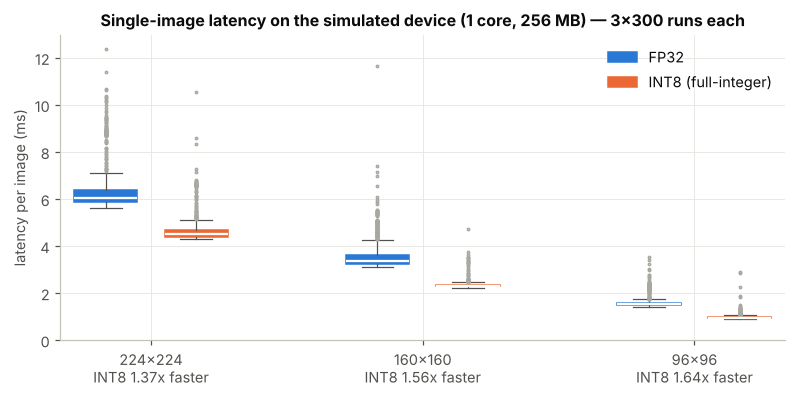

In [24]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
pos, data, cols = [], [], []
for i, res in enumerate(RESOLUTIONS):
    for j, p in enumerate(("fp32", "int8")):
        pos.append(i * 3 + j)
        data.append(np.concatenate([r["lat_ms"] for r in raw[(res, p)]]))
        cols.append(COLOR[p])
bp = ax.boxplot(data, positions=pos, widths=0.7, patch_artist=True, showfliers=True,
                medianprops={"color": "white", "lw": 1.5}, whiskerprops={"color": INK2, "lw": 0.8},
                capprops={"color": INK2, "lw": 0.8},
                flierprops={"marker": ".", "markersize": 3, "markeredgecolor": "#a9a8a0"})
for patch, c in zip(bp["boxes"], cols):
    patch.set(facecolor=c, edgecolor=c)
ticks = []
for res in RESOLUTIONS:
    f, q = (np.mean(np.concatenate([r["lat_ms"] for r in raw[(res, p)]])) for p in ("fp32", "int8"))
    ticks.append(f"{res}x{res}\nINT8 {f / q:.2f}x faster")
ax.set_xticks([i * 3 + 0.5 for i in range(len(RESOLUTIONS))], ticks)
ax.set_ylabel("latency per image (ms)")
ax.set_ylim(0, max(np.percentile(d, 99.5) for d in data) * 1.25)
ax.set_title(f"Single-image latency on the simulated device (1 core, 256 MB) — {N_REPEATS}x{N_RUNS} runs each")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR[p]) for p in ("fp32", "int8")],
          labels=[LABEL["fp32"], LABEL["int8"]], loc="upper right")
savefig(fig, "fig3_latency_distribution.png")
plt.show()

## 9. Accuracy on the device

All 3,925 evaluation images are classified **inside the sandbox**, one image at a time, by the same LiteRT runtime
and the same `.tflite` files that were benchmarked. The images are streamed from disk in chunks, as from flash
storage. The linear-camera case-study models are evaluated on the linear-light version of the same images.

In [25]:
acc_rows, PRED = [], {}
t0 = time.perf_counter()
for key in DEVICE_MODELS:
    images = VAL_LINEAR_NPY if key in CASE_KEYS else VAL_NPY[key[0]]
    r = device.run(WORKER + ["eval", TFLITE[key], images, LABELS_NPY])
    assert r["returncode"] == 0 and r["result"], r
    res_ = r["result"]
    PRED[key] = np.array(res_["pred_top1"])
    acc_rows.append({"resolution": key[0], "precision": key[1], "images": res_["n"],
                     "top-1": res_["top1"], "top-5": res_["top5"],
                     "on-device eval time (s)": res_["eval_seconds"],
                     "peak RSS during eval (MB)": res_["rss_peak"] / 2**20})
print(f"on-device evaluation took {time.perf_counter() - t0:.0f} s")
acc_df = pd.DataFrame(acc_rows)
for res in RESOLUTIONS + sorted({k[0] for k in CASE_KEYS}):
    f = acc_df[(acc_df.resolution == res) & (acc_df.precision == "fp32")].iloc[0]
    m = (acc_df.resolution == res) & (acc_df.precision == "int8")
    acc_df.loc[m, "Δ top-1 vs FP32 (pp)"] = 100 * (acc_df.loc[m, "top-1"] - f["top-1"])
    acc_df.loc[m, "FP32/INT8 top-1 agreement"] = (PRED[(res, "fp32")] == PRED[(res, "int8")]).mean()
acc_df.to_csv(os.path.join(RESULT_DIR, "device_accuracy.csv"), index=False)
acc_df.style.hide(axis="index").format(
    {"top-1": "{:.2%}", "top-5": "{:.2%}", "on-device eval time (s)": "{:.0f}",
     "peak RSS during eval (MB)": "{:.0f}", "Δ top-1 vs FP32 (pp)": "{:+.2f}",
     "FP32/INT8 top-1 agreement": "{:.1%}"}, na_rep="")

on-device evaluation took 190 s


resolution,precision,images,top-1,top-5,on-device eval time (s),peak RSS during eval (MB),Δ top-1 vs FP32 (pp),FP32/INT8 top-1 agreement
224,fp32,3925,80.25%,97.38%,26,82,,
224,int8,3925,79.54%,96.94%,20,62,-0.71,92.9%
160,fp32,3925,77.71%,96.38%,15,73,,
160,int8,3925,76.87%,96.08%,10,54,-0.84,91.3%
96,fp32,3925,67.39%,89.91%,7,68,,
96,int8,3925,61.22%,86.17%,4,49,-6.17,75.7%
224-linear-pow,fp32,3925,79.67%,96.99%,31,83,,
224-linear-pow,int8,3925,78.60%,96.48%,28,63,-1.07,92.3%
224-linear-explog,fp32,3925,80.64%,97.30%,27,82,,
224-linear-explog,int8,3925,79.69%,96.64%,20,63,-0.94,91.6%


In [26]:
# 95% confidence interval of a top-1 difference (paired, McNemar-style normal approximation)
def paired_ci(a_correct, b_correct):
    d = b_correct.astype(float) - a_correct.astype(float)
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))

rows = []
for res in RESOLUTIONS:
    fc, qc = (PRED[(res, p)] == val_labels for p in ("fp32", "int8"))
    m, h = paired_ci(fc, qc)
    rows.append({"resolution": res, "INT8 − FP32 top-1 (pp)": 100 * m, "95% CI (pp)": f"±{100 * h:.2f}",
                 "FP32 right, INT8 wrong": int((fc & ~qc).sum()), "INT8 right, FP32 wrong": int((~fc & qc).sum())})
pd.DataFrame(rows).style.hide(axis="index").format({"INT8 − FP32 top-1 (pp)": "{:+.2f}"})

resolution,INT8 − FP32 top-1 (pp),95% CI (pp),"FP32 right, INT8 wrong","INT8 right, FP32 wrong"
224,-0.71,±0.68,106,78
160,-0.84,±0.71,119,86
96,-6.17,±1.15,394,152


**Why does 96 px lose much more accuracy under INT8?** The cell below measures, on every 5th validation image,
how *close* the FP32 decisions are (top-1 − top-2 probability margin) and how often INT8 changes the top-1
prediction, separately for small- and large-margin images.

In [27]:
rows = []
for res in RESOLUTIONS:
    sample = np.asarray(np.load(VAL_NPY[res], mmap_mode="r")[::5])
    pf, pq = tflite_scores(TFLITE[(res, "fp32")], sample), tflite_scores(TFLITE[(res, "int8")], sample)
    top2 = np.sort(pf, axis=1)[:, -2:]
    margin = top2[:, 1] - top2[:, 0]
    flip = pf.argmax(1) != pq.argmax(1)
    low = margin < 0.1
    rows.append({"resolution": res, "images": len(sample), "median FP32 confidence": np.median(top2[:, 1]),
                 "median margin (p1 − p2)": np.median(margin), "share with margin < 0.1": low.mean(),
                 "INT8 flips: margin < 0.1": flip[low].mean(), "INT8 flips: margin ≥ 0.1": flip[~low].mean(),
                 "INT8 flips: all": flip.mean()})
pd.DataFrame(rows).style.hide(axis="index").format(precision=3).format(
    {c: "{:.1%}" for c in ["share with margin < 0.1", "INT8 flips: margin < 0.1", "INT8 flips: margin ≥ 0.1",
                           "INT8 flips: all"]})

resolution,images,median FP32 confidence,median margin (p1 − p2),share with margin < 0.1,INT8 flips: margin < 0.1,INT8 flips: margin ≥ 0.1,INT8 flips: all
224,785,0.754896,0.678940,11.1%,39.1%,3.3%,7.3%
160,785,0.739357,0.676971,14.9%,47.0%,3.6%,10.1%
96,785,0.565610,0.458658,18.6%,63.0%,14.9%,23.8%


## 10. Latency–accuracy–memory trade-off surface

Each deployed configuration is a point in a 3-D space: **mean latency** (lower is better), **peak memory**
(lower is better) and **top-1 accuracy** (higher is better). A configuration is **Pareto-optimal** if no other
configuration is at least as good on all three axes and strictly better on one.

In [28]:
summary = main_bench.merge(acc_df[acc_df.resolution.isin(RESOLUTIONS)], on=["resolution", "precision"])
summary["GMACs"] = [OPS[(r, p)][0]["MACs"].sum() / 1e9 for r, p in zip(summary.resolution, summary.precision)]

def pareto(df, maximise=("top-1",), minimise=("latency mean (ms)", "peak RSS (MB)")):
    flags = []
    for i, a in df.iterrows():
        dominated = False
        for j, b in df.iterrows():
            if i == j:
                continue
            ge = all(b[c] >= a[c] for c in maximise) and all(b[c] <= a[c] for c in minimise)
            gt = any(b[c] > a[c] for c in maximise) or any(b[c] < a[c] for c in minimise)
            dominated |= ge and gt
        flags.append(not dominated)
    return flags

summary["Pareto-optimal"] = pareto(summary)
cols = ["resolution", "precision", "model size (MB)", "GMACs", "top-1", "top-5", "latency mean (ms)",
        "latency p95 (ms)", "throughput (FPS)", "peak RSS (MB)", "model-attributable (MB)", "Pareto-optimal"]
summary[cols].to_csv(os.path.join(RESULT_DIR, "tradeoff_summary.csv"), index=False)
summary[cols].style.hide(axis="index").format(precision=2).format(
    {"top-1": "{:.2%}", "top-5": "{:.2%}", "throughput (FPS)": "{:.0f}", "GMACs": "{:.3f}"})

resolution,precision,model size (MB),GMACs,top-1,top-5,latency mean (ms),latency p95 (ms),throughput (FPS),peak RSS (MB),model-attributable (MB),Pareto-optimal
224,fp32,14.011808,0.301,80.25%,97.38%,6.386697,8.879330,157,72.460938,38.569010,True
224,int8,4.040904,0.301,79.54%,96.94%,4.673226,5.819620,214,48.731771,14.846354,True
160,fp32,14.011812,0.154,77.71%,96.38%,3.665035,5.004740,273,68.270833,34.391927,True
160,int8,4.040904,0.154,76.87%,96.08%,2.351556,2.519465,425,47.000000,13.149740,True
96,fp32,14.010708,0.056,67.39%,89.91%,1.618144,2.269090,618,65.475260,31.604167,True
96,int8,4.039976,0.056,61.22%,86.17%,0.985989,1.114920,1014,45.889323,12.006510,True


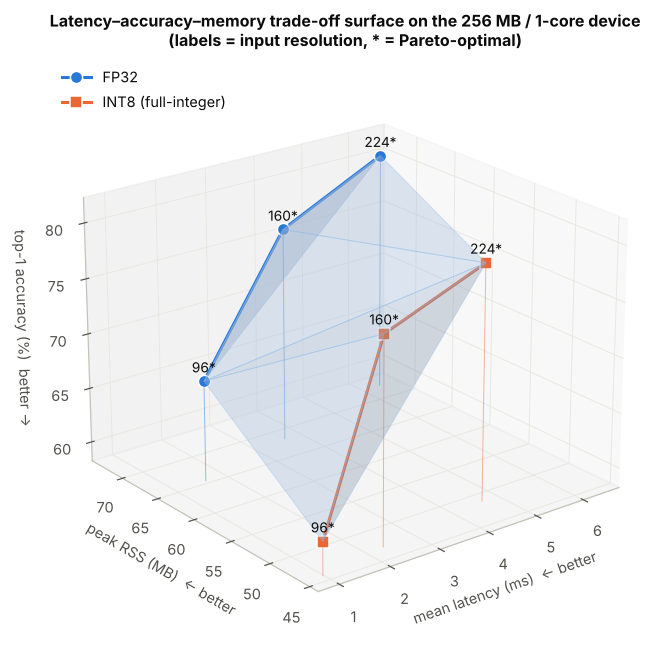

In [29]:
from matplotlib.tri import Triangulation
fig = plt.figure(figsize=(9.5, 7))
ax = fig.add_subplot(projection="3d")
x, y, z = summary["latency mean (ms)"], summary["peak RSS (MB)"], 100 * summary["top-1"]
tri = Triangulation(x, y)
ax.plot_trisurf(x, y, z, triangles=tri.triangles, color="#b7d3f6", alpha=0.35, edgecolor="#86b6ef", lw=0.6)
for p in ("fp32", "int8"):
    s = summary[summary.precision == p].sort_values("resolution")
    ax.plot(s["latency mean (ms)"], s["peak RSS (MB)"], 100 * s["top-1"], color=COLOR[p], lw=2,
            marker=MARKER[p], markersize=8, markeredgecolor="white", label=LABEL[p])
    for _, r in s.iterrows():
        ax.plot([r["latency mean (ms)"]] * 2, [r["peak RSS (MB)"]] * 2, [z.min() - 3, 100 * r["top-1"]],
                color=COLOR[p], lw=0.6, alpha=0.5)
        ax.text(r["latency mean (ms)"], r["peak RSS (MB)"], 100 * r["top-1"] + 0.8,
                f"{r['resolution']}" + ("*" if r["Pareto-optimal"] else ""), fontsize=9, ha="center")
ax.set_xlabel("mean latency (ms)  ← better")
ax.set_ylabel("peak RSS (MB)  ← better")
ax.set_zlabel("top-1 accuracy (%)  better →")
ax.set_zlim(z.min() - 3, z.max() + 2)
ax.view_init(elev=22, azim=-128)
ax.set_title("Latency–accuracy–memory trade-off surface on the 256 MB / 1-core device\n"
             "(labels = input resolution, * = Pareto-optimal)")
ax.legend(loc="upper left")
savefig(fig, "fig4_tradeoff_surface_3d.png")
plt.show()

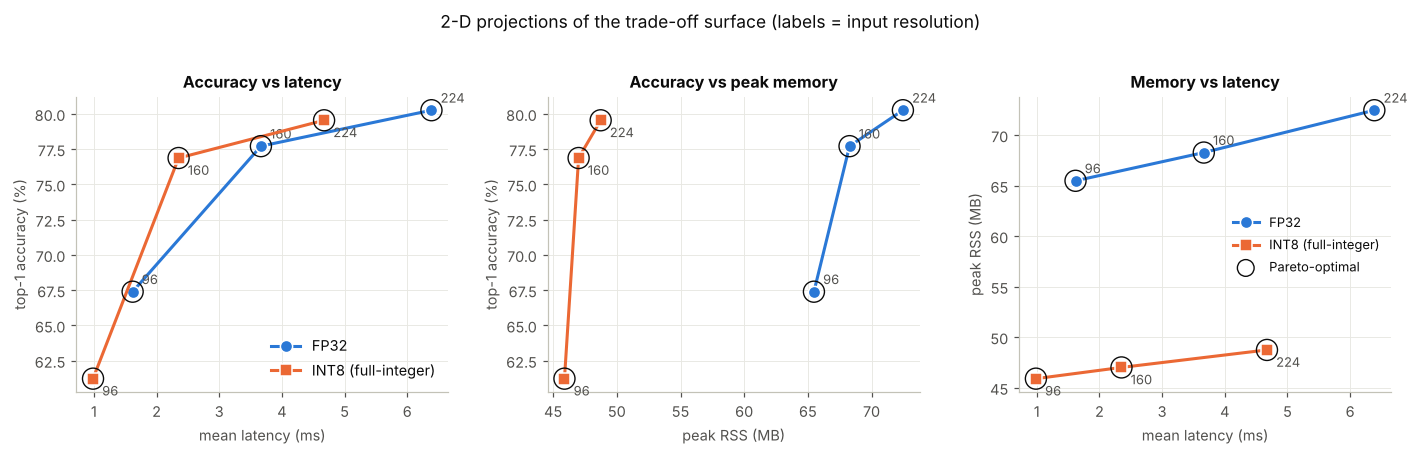

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
pairs = [("latency mean (ms)", "top-1", "mean latency (ms)", "top-1 accuracy (%)"),
         ("peak RSS (MB)", "top-1", "peak RSS (MB)", "top-1 accuracy (%)"),
         ("latency mean (ms)", "peak RSS (MB)", "mean latency (ms)", "peak RSS (MB)")]
for ax, (xc, yc, xl, yl) in zip(axes, pairs):
    scale = 100 if yc == "top-1" else 1
    for p in ("fp32", "int8"):
        s = summary[summary.precision == p].sort_values("resolution")
        ax.plot(s[xc], scale * s[yc], color=COLOR[p], marker=MARKER[p], markeredgecolor="white",
                markersize=8, label=LABEL[p], zorder=3)
        for _, r in s.iterrows():
            ax.annotate(f"{r['resolution']}", (r[xc], scale * r[yc]), textcoords="offset points",
                        xytext=(6, -11 if p == "int8" else 5), fontsize=8.5, color=INK2)
            if r["Pareto-optimal"]:
                ax.scatter(r[xc], scale * r[yc], s=190, facecolor="none", edgecolor="#0b0b0b",
                           lw=0.9, zorder=4)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
axes[0].set_title("Accuracy vs latency")
axes[1].set_title("Accuracy vs peak memory")
axes[2].set_title("Memory vs latency")
axes[0].legend(loc="lower right")
axes[2].scatter([], [], s=120, facecolor="none", edgecolor="#0b0b0b", lw=0.9, label="Pareto-optimal")
axes[2].legend(loc="center right", fontsize=8.5)
fig.suptitle("2-D projections of the trade-off surface (labels = input resolution)", y=1.02)
fig.tight_layout()
savefig(fig, "fig5_tradeoff_projections.png")
plt.show()

## 11. Case study: what a float fallback costs

The linear-camera models from Section 5.5 are compared with the clean model on the same device and the same 3,925
images. The linear-camera models see the linear-light versions of the images.

In [31]:
case = []
for key, desc in [((CASE_RES, "fp32"), "clean MobileNetV2 — FP32"),
                  ((CASE_RES, "int8"), "clean MobileNetV2 — INT8 (all ops integer)"),
                  ((f"{CASE_RES}-linear-pow", "fp32"), "linear camera + POW gamma — FP32"),
                  ((f"{CASE_RES}-linear-pow", "int8"), "linear camera + POW gamma — INT8 with float island"),
                  ((f"{CASE_RES}-linear-explog", "fp32"), "linear camera + exp/log gamma — FP32"),
                  ((f"{CASE_RES}-linear-explog", "int8"), "linear camera + exp/log gamma — INT8 (all integer)")]:
    b, a = pick(bench_df, *key), pick(acc_df, *key)
    v = variant_summary(key, *OPS[key])
    case.append({"model": desc, "top-1": a["top-1"], "Δ vs own FP32 (pp)": a.get("Δ top-1 vs FP32 (pp)"),
                 "latency mean (ms)": b["latency mean (ms)"], "peak RSS (MB)": b["peak RSS (MB)"],
                 "float kernels": v["float kernels"], "Q/DQ boundaries": v["QUANTIZE/DEQUANTIZE boundaries"],
                 "MACs before 1st float op": v["MACs before 1st float op"]})
case_df = pd.DataFrame(case)
case_df.to_csv(os.path.join(RESULT_DIR, "fallback_case_study.csv"), index=False)
clean_q = case_df.iloc[1]["latency mean (ms)"]
for i, name in [(3, "POW float island"), (5, "exp/log INT8 rewrite")]:
    d = case_df.iloc[i]["latency mean (ms)"] - clean_q
    print(f"{name:22s}: {d:+.2f} ms per image vs clean INT8 ({d / clean_q:+.0%})")
case_df.style.hide(axis="index").format({"top-1": "{:.2%}", "Δ vs own FP32 (pp)": "{:+.2f}",
                                         "latency mean (ms)": "{:.2f}", "peak RSS (MB)": "{:.1f}",
                                         "MACs before 1st float op": "{:.0%}"}, na_rep="")

POW float island      : +2.27 ms per image vs clean INT8 (+48%)
exp/log INT8 rewrite  : +0.07 ms per image vs clean INT8 (+1%)


model,top-1,Δ vs own FP32 (pp),latency mean (ms),peak RSS (MB),float kernels,Q/DQ boundaries,MACs before 1st float op
clean MobileNetV2 — FP32,80.25%,,6.39,72.5,67,0,0%
clean MobileNetV2 — INT8 (all ops integer),79.54%,-0.71,4.67,48.7,0,0,100%
linear camera + POW gamma — FP32,79.67%,,7.67,73.7,70,0,0%
linear camera + POW gamma — INT8 with float island,78.60%,-1.07,6.94,49.8,1,2,0%
linear camera + exp/log gamma — FP32,80.64%,,6.55,72.5,74,0,0%
linear camera + exp/log gamma — INT8 (all integer),79.69%,-0.94,4.74,48.9,0,0,100%


### 11.1 A silent quantisation failure found along the way

The first version of the linear-camera model wrote the gamma step as `255 * pow(x/255, 1/2.2)` followed by the
usual `Rescaling(1/127.5, -1)`, i.e. it scaled the image down to [0, 1] and back up to [0, 255]. In FP32 this is
harmless. After full-integer conversion, however, **top-1 collapsed from about 79 % to about 14 %**. The cell below
reproduces the failure. It reads the quantisation parameters of every pre-processing tensor straight from the
interpreter, and adds a control with no float op at all (`255 * (x/255)`, mathematically the identity).

In [32]:
def preprocessing_trace(blob, image):
    # Scale / zero-point / number of distinct values of every tensor before the first convolution.
    with quiet():
        it = Interpreter(model_content=blob, experimental_preserve_all_tensors=True)
        it.allocate_tensors()
    details = {t["index"]: t for t in it.get_tensor_details()}
    it.set_tensor(it.get_input_details()[0]["index"], image[None])
    it.invoke()
    rows = []
    for op in it._get_ops_details():
        if op["op_name"] == "CONV_2D":
            break
        t = details[op["outputs"][0]]
        scale, zp = t["quantization"]
        rows.append({"op": op["op_name"], "dtype": t["dtype"].__name__,
                     "scale": scale if scale else np.nan, "zero-point": zp if scale else np.nan,
                     "distinct values (1 image)": len(np.unique(it.get_tensor(op["outputs"][0])))})
    return pd.DataFrame(rows)

def quick_top1(blob, images, labels):
    with quiet():
        it = Interpreter(model_content=blob, num_threads=os.cpu_count())
        it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    hits = 0
    for img, y in zip(images, labels):
        it.set_tensor(inp["index"], img[None])
        it.invoke()
        hits += int(np.argmax(it.get_tensor(out["index"])[0]) == y)
    return hits / len(labels)

def scale_down_up_model(fn, res=CASE_RES):
    inputs = tf.keras.Input((res, res, 3))
    x = tf.keras.layers.Lambda(fn)(inputs)
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1.0)(x)
    return tf.keras.Model(inputs, KERAS[res].layers[-1](x))

check_idx = np.arange(0, len(val_labels), 13)                     # 302 images
check_images = np.asarray(np.load(VAL_LINEAR_NPY, mmap_mode="r")[check_idx])
pitfall = {"255·pow(x/255, 1/2.2) → Rescaling(1/127.5, −1)":
               lambda v: 255.0 * tf.pow(v / 255.0 + 1e-6, 1.0 / GAMMA),
           "control: 255·(x/255) → Rescaling(1/127.5, −1)  (identity, no float op)":
               lambda v: 255.0 * (v / 255.0)}
rows = []
for name, fn in pitfall.items():
    blob = convert(scale_down_up_model(fn), "int8", calib_linear)
    trace = preprocessing_trace(blob, check_images[0])
    worst = trace.loc[trace["distinct values (1 image)"].idxmin()]
    rows.append({"model": name, "INT8 top-1 (302 images)": quick_top1(blob, check_images, val_labels[check_idx]),
                 "fewest distinct values in a pre-processing tensor": int(worst["distinct values (1 image)"]),
                 "scale on that tensor": worst["scale"]})
    if not rows[:-1]:
        print("Trace of the first model (tensor values for one image):")
        display(trace.style.hide(axis="index").format({"scale": "{:.5g}", "zero-point": "{:.0f}"}, na_rep="—"))
pd.DataFrame(rows).style.hide(axis="index").format({"INT8 top-1 (302 images)": "{:.1%}", "scale on that tensor": "{:.4g}"})

Trace of the first model (tensor values for one image):


op,dtype,scale,zero-point,distinct values (1 image)
QUANTIZE,int8,1,-128,184
MUL,int8,0.0039216,-128,184
ADD,int8,0.0039216,-128,184
DEQUANTIZE,float32,—,—,184
POW,float32,—,—,184
QUANTIZE,int8,1,-128,2
MUL,int8,1,-128,2
MUL,int8,0.01175,-43,2
ADD,int8,0.0078284,-1,2


model,INT8 top-1 (302 images),fewest distinct values in a pre-processing tensor,scale on that tensor
"255·pow(x/255, 1/2.2) → Rescaling(1/127.5, −1)",14.2%,2,1
"control: 255·(x/255) → Rescaling(1/127.5, −1) (identity, no float op)",6.3%,2,1


**Diagnosis.** In both models, the tensor that holds the image in the 0–1 range was given **scale = 1.0**, the
scale of the 0–255 tensor that follows it, instead of its calibrated ≈ 1/255. Every pixel is therefore rounded to
0 or 1, and the network sees a 2-level image. The control proves that the float island is *not* the cause: the
all-integer identity graph fails in the same way, while the `pow` model with the down/up scaling removed (Section
11 table) is fine. The converter printed no warning, and the FlatBuffer is perfectly valid. The only signs were
the quantisation parameters read from the file and the accuracy measured on the device.

The fix is simply not to scale down and back up: let one `Rescaling` do the affine map, as in Section 5.5. The
general lesson for deployment is that **every quantised model has to be re-validated end to end, on the target
runtime, on real data**. "It converted without errors" says nothing about whether it still works.

## 12. Written report

### 12.1 Aim and approach

The goal was to take an ImageNet-pre-trained **MobileNetV2** through the deployment path used for mobile and
embedded vision, and to measure the result under realistic device constraints. The steps were: post-training
**full-integer quantisation** with the TFLite converter (calibrated on 300 representative images), **verification
of the FlatBuffer** to see what actually got quantised, and measurement of **latency, peak memory and accuracy**
on a device limited to **256 MB of RAM and one CPU core**, at 224×224, 160×160 and 96×96 input resolution. The
device was emulated with Linux cgroups. The 256 MB limit is enforced by the kernel: a 300 MB allocation inside the
sandbox was OOM-killed. Only the stand-alone LiteRT runtime runs on the device: importing it costs 33 MB,
while importing full TensorFlow costs 520 MB, more than the entire device.

### 12.2 Results

| input | precision | file (MB) | GMACs | top-1 | top-5 | mean latency (ms) | p95 (ms) | peak RSS (MB) | model-attributable (MB) |
|---|---|---|---|---|---|---|---|---|---|
| 224×224 | FP32 | 14.01 | 0.301 | 80.25% | 97.38% | 6.39 | 8.88 | 72.5 | 38.6 |
| 224×224 | **INT8** | 4.04 | 0.301 | 79.54% | 96.94% | 4.67 | 5.82 | 48.7 | 14.8 |
| 160×160 | FP32 | 14.01 | 0.154 | 77.71% | 96.38% | 3.67 | 5.00 | 68.3 | 34.4 |
| 160×160 | **INT8** | 4.04 | 0.154 | 76.87% | 96.08% | 2.35 | 2.52 | 47.0 | 13.1 |
| 96×96 | FP32 | 14.01 | 0.056 | 67.39% | 89.91% | 1.62 | 2.27 | 65.5 | 31.6 |
| 96×96 | **INT8** | 4.04 | 0.056 | 61.22% | 86.17% | 0.99 | 1.11 | 45.9 | 12.0 |

1. **What got quantised.** In the integer-only model, all 67 compute operators run on
   INT8 kernels (35× `CONV_2D`, 17× `DEPTHWISE_CONV_2D`, 11× `ADD`, 1× `MUL`, 1× `MEAN`, 1× `FULLY_CONNECTED`, 1× `SOFTMAX`). ReLU6 needs no operator of its own: it is fused into the convolutions as the clamp
   of an int8 output range with scale 6/255. Weights are int8 with symmetric per-channel scales, biases are int32
   with scale *s*<sub>in</sub>·*s*<sub>w</sub>, and activations are int8 with a per-tensor scale and zero-point.
   The variant that allows float fallback with float32 I/O differs only by a `QUANTIZE` at the input and a
   `DEQUANTIZE` at the output. MobileNetV2 is a "friendly" architecture: ReLU6 bounds every activation, batch-norm
   folds into the convolutions, and it uses no exotic non-linearities.
2. **Latency.** INT8 was 1.37× / 1.56× / 1.64× faster than FP32 at 224 / 160 /
   96 px. Lowering the resolution helps far more: 224 → 96 px cuts the MACs 5.3× and the
   INT8 latency 4.7×. The 95th
   percentile is at most 40% above the mean,
   and every run kept exactly one core busy.
3. **Memory.** The file is 3.47× smaller. The memory attributable to the model at run time
   (memory-mapped weights + XNNPACK packed weights + tensor arena) drops from
   38.6 MB to 14.8 MB at
   224 px (2.6×). Resolution matters much less here, because the weights are the same 3.5 M
   parameters at every size and only the activation arena shrinks. Peak RSS never exceeded 72 MB, so
   even FP32 fits on this device. On a microcontroller with a few hundred **kB** of SRAM, the 4× smaller tensors
   are what make deployment possible at all.
4. **Accuracy.** INT8 costs 0.71 pp (95 % CI ±0.68) at 224 px and
   0.84 pp (±0.71) at 160 px. This is in line with the ≈1 pp drop typically reported
   for post-training-quantised MobileNetV2-224. At **96 px the loss is 6.17 pp**
   (±1.15). The margin analysis in Section 9 shows two effects. First, the 96 px model is less
   certain: 19% of its images have an FP32 top-1 − top-2 margin below 0.1
   (vs 11% at 224 px), and INT8 flips 63%
   of those. Second, even *confident* images flip more often: 14.9% versus
   3.3% at 224 px. A plausible reason for the second effect is that the
   final 1280-channel feature map is only 3×3 at 96 px instead of 7×7 at 224 px. Global average pooling therefore
   averages the accumulated quantisation noise over 9 positions instead of 49. The per-layer analysis (Section 6)
   shows where the error comes from. It is concentrated in the early **depthwise** convolutions: their mean error
   is 0.41 quantisation steps versus 0.34 for regular convolutions, and the worst layer is
   `expanded_conv_depthwise_relu` at 1.40 steps, 4.8× the error of pure rounding. This matches the known
   sensitivity of depthwise layers in MobileNets (Sheng et al., 2018; Nagel et al., 2019). Each output depends on
   only 9 weights, so rounding errors do not average out, and channels with very different output ranges must
   share one per-tensor activation scale.
5. **Trade-off surface.** All six configurations are Pareto-optimal: each one buys speed or memory with accuracy,
   so the "best" choice depends on the application's budget. The curve has a clear knee at **INT8-160**. Going
   from INT8-224 to INT8-160 saves 50 %
   of the latency for 2.7 pp. Going on to INT8-96
   saves another 1.4 ms but costs
   15.6 pp. If 96 px is required, FP32-96 is
   6.2 pp
   more accurate than INT8-96 for 0.63 ms
   more. Quantisation-aware training would be the way to get both.

### 12.3 Why not all TFLite operators support INT8 quantisation

In TFLite's integer scheme a real value is stored as *r* = *s*·(*q* − *z*): an 8-bit integer *q*, a float scale
*s* and a zero-point *z* fixed at conversion time. An "INT8 operator" is therefore **not** the float operator
applied to int8 numbers. It is a separate, hand-written kernel that must produce the int8 output *q*<sub>y</sub>
directly from the int8 inputs, using only integer arithmetic. Several things stand in the way of writing one for
every operator:

1. **The scale only factors out of linear operations.** For convolution, fully-connected, add and average-pool,
   the scales factor out of the sum. The kernel accumulates (*q*<sub>x</sub> − *z*<sub>x</sub>)·*q*<sub>w</sub>
   in int32 and rescales once with a fixed-point multiplier *M* = *s*<sub>x</sub>*s*<sub>w</sub>/*s*<sub>y</sub>
   (an int32 multiplier plus a shift). Piece-wise linear activations (ReLU, ReLU6) are just a clamp on the output
   range. A **non-linear** function *f* gives no such shortcut: *f*(*s*(*q* − *z*)) is not an affine function of
   *q*. Each non-linear op needs its own approximation, either a 256-entry lookup table (TFLite does this for
   sigmoid, tanh, exp, log and gelu, which the probe showed have INT8 kernels) or a fixed-point polynomial or
   Newton iteration (rsqrt, softmax, l2-normalise). Each of these has to be designed, checked for accuracy,
   optimised for every CPU back-end (reference, ARM NEON, x86, XNNPACK) and maintained.
2. **Engineering priority.** TFLite has well over a hundred builtin operators, and INT8 kernels exist mainly for
   the ones that popular edge models use. HARD_SWISH gained one for MobileNetV3, and GELU and EXP/LOG were added
   as transformer-style models moved to the edge. The long tail is still float-only. In this version (TF
   2.21) the probe found **10 float-only ops out of 23 tested**:
   `square`, `pow (x^1.5)`, `sin`, `cos`, `floor`, `round`, `sign`, `elu`, `cumsum`, `atan2`. Some of these are not mathematically hard (`square(x)` is just
   `mul(x, x)`, which has an INT8 kernel); nobody has written the kernel.
3. **Range and resolution.** A single (*s*, *z*) per tensor gives 256 evenly spaced levels over a range fixed at
   calibration. Ops whose output range is **unbounded or input-dependent** fit this badly: `pow`, `square` and
   `exp` of large inputs expand the dynamic range, and `cumsum` grows with sequence length. Most levels are wasted,
   or the output saturates whenever deployment data exceed the calibrated range. Ops with **steep or periodic**
   responses (`sin`/`cos` of large arguments, `atan2` near the origin) turn a one-step input error into a large
   output error.
4. **Integer-valued and discontinuous ops.** `floor`, `round` and `sign` are defined on the *real* value. On a
   quantised tensor the integer grid of *q* is not the integer grid of *r*, so the kernel has to de-quantise
   anyway. The step-shaped output is also maximally sensitive to rounding error near each discontinuity.
5. **Constraints of the quantisation specification.** The TFLite INT8 spec requires symmetric per-channel weights,
   int32 biases with a fixed scale, and *identical* input and output scales for ops such as concatenation, pad,
   reshape and max-pool. An op whose semantics do not fit these rules needs special handling, or stays in float.
6. **Ops that are not TFLite builtins at all.** These include `erf` (exact GELU), custom ops, and any op that has
   to go through the Flex delegate (`SELECT_TF_OPS`). They only exist as float TensorFlow kernels. In the probe,
   `erf` made conversion fail outright.
7. **Accelerators support even less.** NPUs, DSPs and TPUs such as the Edge TPU, Arm Ethos-U and Hexagon are
   fixed-function integer MAC arrays with a short list of supported ops. An op that is INT8 on the CPU can still
   be unsupported on the accelerator.

### 12.4 Consequences for real edge deployment

1. **"Full-integer" is a request, not a guarantee.** With `supported_ops = [TFLITE_BUILTINS_INT8]` and int8 I/O,
   the converter still produced float islands (`DEQUANTIZE → op → QUANTIZE`) **without any error** for every
   float-only op in the probe. The only reliable check is to inspect the FlatBuffer, as in Section 5, or the
   accelerator compiler's report, and to fail the build in CI if a float tensor appears.
2. **Accelerator partitioning.** An integer-only accelerator cannot execute a float op, so the graph is split and
   the float part runs on the CPU. Every split adds a transfer and a synchronisation between accelerator and CPU.
   The Edge TPU compiler documents that it partitions only **once**: everything from the first unsupported op
   onwards runs on the CPU. In the case study a single `POW` at the start of MobileNetV2 dropped the share of MACs
   such an accelerator could run from **100 % to 0 %**. The 10–100× speed-up that was the reason for buying the
   accelerator would simply disappear.
3. **Latency overhead even on the CPU.** The island needs a de-quantise, a float kernel and a re-quantise over the
   whole tensor. For one `POW` on the 224×224×3 input this cost **+2.27 ms per image
   (+48%)** on the device, which is more than the entire FP32→INT8 gain
   at that resolution
   (1.71 ms). An island
   deeper in the network, on a large feature map, would cost more.
4. **Memory.** Float tensors are 4× larger than int8 ones, and the arena must hold the largest of them. Peak RSS
   rose from 48.7 MB to 49.8 MB here. That is irrelevant at
   256 MB, but decisive on a microcontroller with 256–512 kB of SRAM. A float op also forces the float kernel and
   (on an MCU without an FPU) a software floating-point library to be linked into the firmware.
5. **No FPU, no float.** Cortex-M0/M0+/M3-class MCUs and many DSPs have no floating-point unit. On them a float
   island is either emulated in software (orders of magnitude slower) or not available in TFLite Micro at all, in
   which case the model cannot be deployed.
6. **Accuracy and energy.** Each extra quantise/de-quantise pair adds rounding error and needs its own calibrated
   range, and float arithmetic costs far more energy per operation than 8-bit integer arithmetic (Horowitz, 2014).
   On battery-powered devices this matters as much as latency.
7. **Silent numerical failures must be caught by validation.** A converter quirk, unrelated to float fallback,
   assigned a 0–1 tensor the scale of a neighbouring 0–255 tensor (Section 11.1). The image was reduced to 2 grey
   levels and top-1 fell to 14.2% with no warning. Quantised models must be re-validated end to end, on the target runtime and on real data,
   after every conversion.

**Mitigations.** Prefer architectures and activations with INT8 kernels (ReLU6/hard-swish rather than ELU or
erf-GELU). Rewrite unsupported ops from supported ones: the exp/log form of the gamma curve gave an all-integer
graph (100 % accelerator coverage, +0.07 ms vs the clean model) at
79.69 % top-1 versus 78.60 % for the `POW` island. Move pre- and
post-processing out of the model (a 256-entry uint8 lookup table applied on the CPU costs almost nothing). Use the
16x8 mode (int16 activations, int8 weights) or selective quantisation for sensitive layers. Use
quantisation-aware training when post-training quantisation loses too much accuracy, as at 96 px here.

### 12.5 Limitations

* The host CPU is a server-class Xeon with AVX-512 VNNI. Absolute latencies are far lower than on a Cortex-A53/A72
  board, and the INT8/FP32 speed ratio is CPU-dependent (typically larger on ARM cores with dot-product
  instructions). The cgroup sandbox reproduces the **memory capacity and core count** of the device, not its clock
  speed, cache sizes or memory bandwidth.
* Imagenette images come from ImageNet, so some may have been in MobileNetV2's training data, and its 10 classes
  are relatively easy. Absolute top-1 is therefore higher than the ≈72 % reported on the ImageNet validation set.
  The FP32-vs-INT8 and resolution *comparisons* are unaffected, because every model sees the same images.
* Peak RSS includes ~34 MB for the Python interpreter, NumPy and LiteRT. A C++ deployment would
  have a smaller fixed cost; the *model-attributable* column is the portable number.
* Only post-training quantisation was studied. Quantisation-aware training would likely recover most of the
  96 px loss.

### 12.6 Conclusion

Full-integer post-training quantisation turned MobileNetV2 into a 4.0 MB, integer-only model that
runs 1.4–1.6× faster and uses ~2.6× less
model memory on a single core, for under 1 pp of top-1 at 224 and 160 px. Every MobileNetV2 operator had an INT8
kernel. That is a property of the architecture, not of the converter: as soon as an operator without an INT8
kernel appears, the converter silently falls back to float. The cost is extra latency, memory and energy on the
CPU, and, on integer-only accelerators, the loss of acceleration altogether. Edge deployment therefore has to
include inspecting the converted FlatBuffer and validating accuracy on the device, not just running the converter.
For this device, **INT8 MobileNetV2 at 160×160** gives the best balance: 76.9 %
top-1, 2.4 ms per image and 47 MB
peak memory.

## 13. References

1. M. Sandler, A. Howard, M. Zhu, A. Zhmoginov, L.-C. Chen. *MobileNetV2: Inverted Residuals and Linear
   Bottlenecks.* CVPR 2018.
2. B. Jacob, S. Kligys, B. Chen, M. Zhu, M. Tang, A. Howard, H. Adam, D. Kalenichenko. *Quantization and Training
   of Neural Networks for Efficient Integer-Arithmetic-Only Inference.* CVPR 2018.
3. R. Krishnamoorthi. *Quantizing deep convolutional networks for efficient inference: A whitepaper.*
   arXiv:1806.08342, 2018.
4. M. Nagel, M. Fournarakis, R. A. Amjad, Y. Bondarenko, M. van Baalen, T. Blankevoort. *A White Paper on Neural
   Network Quantization.* arXiv:2106.08295, 2021.
5. Google AI Edge. *LiteRT 8-bit quantization specification* and *Post-training integer quantization*
   (ai.google.dev/edge/litert).
6. Coral. *TensorFlow models on the Edge TPU*: model requirements and compiler partitioning
   (coral.ai/docs/edgetpu/models-intro).
7. J. Howard. *Imagenette*: a 10-class subset of ImageNet (github.com/fastai/imagenette).
8. Linux kernel documentation. *Control Groups: memory and CPU (CFS bandwidth) controllers.*

9. T. Sheng, C. Feng, S. Zhuo, X. Zhang, L. Shen, M. Aleksic. *A Quantization-Friendly Separable Convolution for
   MobileNets.* EMC² Workshop (ISCA) 2018.
10. M. Nagel, M. van Baalen, T. Blankevoort, M. Welling. *Data-Free Quantization Through Weight Equalization and
    Bias Correction.* ICCV 2019.
11. M. Horowitz. *Computing's energy problem (and what we can do about it).* ISSCC 2014.


---
*Reproducibility:* every number in this notebook is computed by the cells above, which also save their outputs to
`results/*.csv|json` and `figures/*.png`. Re-running from a clean checkout downloads the data (~340 MB) and the
Keras weights automatically. Latencies depend on the host CPU (see Section 1). Re-running gives slightly
different latencies; the accuracies are deterministic.